# Dog Breed Classification Using Deep Learning



This notebook classifies dog photos into breeds. A CNN built from scratch is compared with transfer learning from pretrained ImageNet networks, before and after optimisation.

**Datasets** (merged, cleaned and de-duplicated automatically):
- [Stanford Dogs](http://vision.stanford.edu/aditya86/ImageNetDogs/)
- [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) (dog breeds only)
- [Tsinghua Dogs](https://cg.cs.tsinghua.edu.cn/ThuDogs/)
- [Dog Breeds Image Dataset](https://www.kaggle.com/datasets/darshanthakare/dog-breeds-image-dataset) (Kaggle)
- [Dog Breed Identification](https://www.kaggle.com/c/dog-breed-identification) (Kaggle competition)

**How to run:** Runtime > Change runtime type > T4 GPU, then Runtime > Run all. Paste your Kaggle API token when asked, and accept the rules of the Dog Breed Identification competition once on kaggle.com. Intermediate results are saved to Google Drive (`dog_breed_project/`), so a restarted runtime continues where it stopped.

In [1]:
!pip -q install optuna fastapi uvicorn python-multipart
!pip -q install -U kagglehub kaggle

In [2]:
import os, re, json, math, time, random, shutil, tarfile, zipfile, subprocess, warnings, difflib, gc
from pathlib import Path
from collections import Counter
from multiprocessing import Pool
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **kw):
        return x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CFG = dict(
    # ---- which datasets to merge ----
    use_stanford=True,
    use_oxford=True,
    use_tsinghua=True,
    use_hyperai_dogbreeds=True,   # HyperAI "Dog Breeds" (Kaggle: darshanthakare), ~17k images
    use_kaggle_dogbreed_id=True,  # Kaggle competition "Dog Breed Identification" (10k images, 120 breeds; needs a Kaggle login + accepted rules)
    use_hyperai_wild=False,       # HyperAI "Dogs-in-the-Wild" (Baidu): 30 GB, manual download. See the markdown cell below.
    wild_dir='/content/drive/MyDrive/dog_breed_project/manual/dogs-in-the-wild',
    wild_names_json='/content/drive/MyDrive/dog_breed_project/manual/wild_category_names.json',
    use_drive=True,               # keep cleaned data + tuning history on Google Drive
    # ---- images ----
    img_store=256,                # size of the cleaned images on disk
    img_size=224,                 # size fed to the network (random crop in training, centre crop for val/test)
    # ---- balancing / splitting ----
    min_per_class=20,             # breeds with fewer images (after dedupe) are dropped. Transfer learning copes with ~20+, but their test numbers rest on 2-3 photos
    max_per_class=1500,           # breeds with more are randomly down-sampled (stops a few breeds dominating)
    dup_dist=3,                   # perceptual-hash distance (of 64 bits) treated as "same image"
    alias_min_groups=10,          # learn that two breed names are the same breed if >= this many identical photos carry both names
    alias_min_share=0.6,          # ...and that pairing explains >= this share of each name's shared photos
    dup_max_cluster=8,            # a 'duplicate group' bigger than this is look-alike images, not copies: left untouched
    test_frac=0.10, val_frac=0.10,
    # ---- model ----
    retrain=False,                # True = ignore a trained model saved on Drive and train again
    pretrained='imagenet',
    # ---- architecture comparison: every network below gets the same short training run on a subset ----
    compare_archs=['MobileNet', 'MobileNetV2', 'ResNet50', 'VGG16', 'VGG19', 'InceptionV3', 'EfficientNetB0', 'EfficientNetV2B0'],
    compare_train_images=12000, compare_val_images=3000,
    compare_epochs_head=2, compare_epochs_ft=3,
    tune_top_k=1,                 # tune this many of the best architectures (2 doubles the tuning time)
    # ---- hyperparameter search (runs on a subset to save time) ----
    tune_trials=12, tune_train_images=24000, tune_val_images=5000,
    tune_epochs_head=2, tune_epochs_ft=4,
    # ---- final training ----
    final_epochs_head=3, final_epochs_ft=25,
    # ---- custom CNN and before/after comparison ----
    cnn_epochs=30, cnn_img=128,                              # the from-scratch CNN: max epochs (early stopping usually stops sooner), input size
    baseline_epochs_head=3, baseline_epochs_ft=5,           # transfer learning BEFORE optimisation (default settings, no early stopping)
    n_new_images=12,                                         # unseen photos shown in the 'test with new images' section
)

ROOT = Path('/content/dogs')
RAW, CLEAN, INDEX = ROOT / 'raw', ROOT / 'clean', ROOT / 'clean_index.csv'
for d in (ROOT, RAW, CLEAN):
    d.mkdir(parents=True, exist_ok=True)
S, IMG = CFG['img_store'], CFG['img_size']


def sh(cmd):
    subprocess.run(cmd, shell=True, check=True)

In [3]:
PERSIST = None
if CFG['use_drive']:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PERSIST = Path('/content/drive/MyDrive/dog_breed_project')
        (PERSIST / 'manual').mkdir(parents=True, exist_ok=True)
    except Exception as e:
        print('Google Drive not mounted, so nothing will survive a runtime reset:', e)

RESTORED = False
if PERSIST and (PERSIST / 'clean_images.tar').exists() and (PERSIST / 'clean_index.csv').exists():
    print('Found a saved, cleaned dataset on Drive: restoring it (skips download + preprocessing)...')
    for tar_file in sorted(PERSIST.glob('clean_images*.tar')):
        sh(f'tar -xf "{tar_file}" -C "{ROOT}"')
    shutil.copy(PERSIST / 'clean_index.csv', INDEX)
    RESTORED = True

ENABLED = [k for k, on in [('stanford', CFG['use_stanford']), ('oxford', CFG['use_oxford']), ('tsinghua', CFG['use_tsinghua']),
                           ('hyperai_dogbreeds', CFG['use_hyperai_dogbreeds']), ('kaggle_breedid', CFG['use_kaggle_dogbreed_id']),
                           ('wild', CFG['use_hyperai_wild'])] if on]
HAVE = set(pd.read_csv(INDEX).source) if RESTORED else set()
TODO = [k for k in ENABLED if k not in HAVE]
print('RESTORED =', RESTORED, '| datasets still to fetch and process:', TODO or 'none, everything is already in the saved dataset')

Mounted at /content/drive
Found a saved, cleaned dataset on Drive: restoring it (skips download + preprocessing)...
RESTORED = True | datasets still to fetch and process: none, everything is already in the saved dataset


## 1. Dataset acquisition and preparation

Each source is downloaded separately. If one fails (the Tsinghua server is the usual cause), download the file in the browser, put it in `My Drive/dog_breed_project/manual/` under the name shown in the message, and run the cell again.

In [4]:
def get_archive(name, url, manual_name=None):
    dest = RAW / name
    if dest.exists() and any(dest.iterdir()):
        return dest
    archive = RAW / f'{name}.archive'
    manual = (PERSIST / 'manual' / manual_name) if (PERSIST and manual_name) else None
    if manual is not None and manual.exists():
        archive = manual
    else:
        sh(f'wget -q -c --tries=3 -O "{archive}" "{url}"')
    tmp = RAW / f'{name}.tmp'
    shutil.rmtree(tmp, ignore_errors=True)
    tmp.mkdir(parents=True)
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:
            z.extractall(tmp)
    elif tarfile.is_tarfile(archive):
        with tarfile.open(archive) as t:
            try:
                t.extractall(tmp, filter='data')
            except TypeError:
                t.extractall(tmp)
    else:
        raise RuntimeError(f'{archive} is not a zip or tar archive (the download probably returned an error page)')
    tmp.rename(dest)
    if archive.parent == RAW:
        archive.unlink()
    return dest


def ensure_kaggle_credentials():
    kdir = Path.home() / '.kaggle'
    kdir.mkdir(exist_ok=True)
    if os.environ.get('KAGGLE_API_TOKEN') or (os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY')) \
            or (kdir / 'access_token').exists() or (kdir / 'kaggle.json').exists():
        return
    token = None
    try:
        from google.colab import userdata
        token = userdata.get('KAGGLE_API_TOKEN')
    except Exception:
        pass
    if not token and PERSIST:
        tf, jf = PERSIST / 'manual' / 'kaggle_token.txt', PERSIST / 'manual' / 'kaggle.json'
        if tf.exists():
            token = tf.read_text().strip()
        elif jf.exists():
            shutil.copy(jf, kdir / 'kaggle.json')
            (kdir / 'kaggle.json').chmod(0o600)
            return
    if not token:
        import getpass
        token = getpass.getpass('Paste your Kaggle API token (Kaggle > Settings > API > Generate New Token), or press Enter to upload a kaggle.json instead: ').strip()
    if not token:
        from google.colab import files
        up = files.upload()
        creds = json.loads(next(iter(up.values())).decode())
        os.environ['KAGGLE_USERNAME'], os.environ['KAGGLE_KEY'] = creds['username'], creds['key']
        return
    os.environ['KAGGLE_API_TOKEN'] = token
    (kdir / 'access_token').write_text(token)
    (kdir / 'access_token').chmod(0o600)


def get_kaggle_dogbreeds():
    dest = RAW / 'hyperai_dogbreeds'
    if dest.exists() and any(dest.iterdir()):
        return dest
    import kagglehub
    ref = 'darshanthakare/dog-breeds-image-dataset'
    try:
        p = kagglehub.dataset_download(ref)
    except Exception:
        ensure_kaggle_credentials()
        p = kagglehub.dataset_download(ref)
    os.symlink(p, dest)
    return dest


def get_kaggle_competition(slug, name):
    dest = RAW / name
    if dest.exists() and any(dest.iterdir()):
        return dest
    ensure_kaggle_credentials()
    tmp = RAW / f'{name}.tmp'
    shutil.rmtree(tmp, ignore_errors=True)
    tmp.mkdir(parents=True)
    r = subprocess.run(['kaggle', 'competitions', 'download', '-c', slug, '-p', str(tmp)], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f'Kaggle download failed. If it mentions 403 or rules: open https://www.kaggle.com/c/{slug}/rules, click "I Understand and Accept", then re-run. Details: {(r.stderr or r.stdout)[-300:]}')
    for _ in range(2):
        for z in list(tmp.rglob('*.zip')):
            if z.name.startswith('test'):
                z.unlink()
                continue
            with zipfile.ZipFile(z) as zf:
                zf.extractall(z.parent)
            z.unlink()
    tmp.rename(dest)
    return dest


SOURCES = {}


def try_get(key, fn):
    try:
        SOURCES[key] = fn()
        print(f'ok   {key}: {SOURCES[key]}')
    except Exception as e:
        print(f'!!   {key}: could not get this dataset ({e}). Continuing without it.')


if TODO:
    if 'stanford' in TODO:
        try_get('stanford', lambda: get_archive('stanford', 'http://vision.stanford.edu/aditya86/ImageNetDogs/images.tar', 'stanford_images.tar'))
    if 'oxford' in TODO:
        try_get('oxford', lambda: get_archive('oxford', 'https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz', 'oxford_images.tar.gz'))
    if 'tsinghua' in TODO:
        try_get('tsinghua', lambda: get_archive('tsinghua', 'https://cloud.tsinghua.edu.cn/f/80013ef29c5f42728fc8/?dl=1', 'tsinghua_low_resolution.zip'))
    if 'hyperai_dogbreeds' in TODO:
        try_get('hyperai_dogbreeds', get_kaggle_dogbreeds)
    if 'kaggle_breedid' in TODO:
        try_get('kaggle_breedid', lambda: get_kaggle_competition('dog-breed-identification', 'kaggle_breedid'))
    if 'wild' in TODO:
        SOURCES['wild'] = Path(CFG['wild_dir'])

### 1.1 Index images and merge breed names

The datasets label images differently (folder names, file names, ids). Each is converted to one table of path, source and label, and spelling variants of the same breed are merged into one class.

In [5]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}


def list_images(root):
    return [p for p in Path(root).rglob('*')
            if p.suffix.lower() in IMG_EXT and '__MACOSX' not in p.parts and not p.name.startswith('._')]


def strip_id(name):
    return re.sub(r'^n?\d+[-_ ]+', '', name, flags=re.I)


def scan_folders(root, source):
    return [(p, source, strip_id(p.parent.name)) for p in list_images(root)]


def scan_oxford(root):
    rows = []
    for p in list_images(root):
        if not p.stem[:1].islower():
            continue
        rows.append((p, 'oxford', re.sub(r'_\d+$', '', p.stem)))
    return rows


def scan_breedid(root):
    lab = next(Path(root).rglob('labels.csv'))
    d = pd.read_csv(lab)
    return [(lab.parent / 'train' / f'{i}.jpg', 'kaggle_breedid', b) for i, b in zip(d['id'], d['breed'])]


def scan_wild(root, names_json):
    root = Path(root)
    names = json.loads(Path(names_json).read_text())
    ann = json.loads((root / 'train.json').read_text())['annotations']
    rows = []
    for a in ann:
        nm = names.get(str(a['category id']))
        if nm:
            rows.append((root / a['name'], 'wild', nm))
    return rows


if TODO:
    rows = []
    if 'stanford' in SOURCES: rows += scan_folders(SOURCES['stanford'], 'stanford')
    if 'oxford' in SOURCES: rows += scan_oxford(SOURCES['oxford'])
    if 'tsinghua' in SOURCES: rows += scan_folders(SOURCES['tsinghua'], 'tsinghua')
    if 'hyperai_dogbreeds' in SOURCES: rows += scan_folders(SOURCES['hyperai_dogbreeds'], 'hyperai_dogbreeds')
    if 'kaggle_breedid' in SOURCES: rows += scan_breedid(SOURCES['kaggle_breedid'])
    if 'wild' in SOURCES:
        try:
            rows += scan_wild(SOURCES['wild'], CFG['wild_names_json'])
        except Exception as e:
            print('!! Dogs-in-the-Wild could not be read:', e)
    df = pd.DataFrame(rows, columns=['path', 'source', 'raw_label'])
    df['path'] = df['path'].astype(str)
    if not len(df):
        assert RESTORED, 'No images found: every dataset failed to download. See the messages above.'
        print('!! None of the new datasets could be fetched; continuing with the saved dataset.')
    print(df.groupby('source').agg(images=('path', 'size'), breeds=('raw_label', 'nunique')))
    for src, g in df.groupby('source'):
        print(f'\n{src}: sample labels ->', sorted(g.raw_label.unique())[:8])
        if g.raw_label.str.match(r'(?i)^n?\d{3,}').any():
            print(f'  WARNING: some {src} labels still start with an id number. Send me a few of them: {list(g.raw_label[g.raw_label.str.match(r"(?i)^n?\d{3,}")].unique()[:3])}')
        if g.raw_label.str.contains('[A-Za-z]').mean() < 0.5:
            print(f'  WARNING: most labels in {src} have no letters (numeric ids?). Breeds from it will not merge with other datasets.')

In [6]:
ALIASES = {
    'stbernard': 'saintbernard',
    'japanesespaniel': 'japanesechin',
    'wheatenterrier': 'softcoatedwheatenterrier',
    'germanshorthaired': 'germanshorthairedpointer',
    'leonberger': 'leonberg',
    'basset': 'bassethound',
    'cockerspaniel': 'englishcockerspaniel',
    'scotchterrier': 'scottishterrier',
    'pembroke': 'pembrokewelshcorgi',
    'cardigan': 'cardiganwelshcorgi',
    'malamute': 'alaskanmalamute',
    'bluetick': 'bluetickcoonhound',
    'bostonbull': 'bostonterrier',
    'maltesedog': 'maltese',
    'lhasa': 'lhasaapso',
    'chow': 'chowchow',
    'pekinese': 'pekingese',
    'doberman': 'dobermanpinscher',
}


def norm_key(s):
    k = re.sub(r'[^a-z0-9]', '', s.lower())
    return ALIASES.get(k, k)


def pretty(s):
    return re.sub(r'\s+', ' ', re.sub(r'[_\-]+', ' ', s)).strip().title()


def merge_breed_names(df, merge_ratio=0.90, near_ratio=0.80):
    df = df.copy()
    df['key'] = df.raw_label.map(norm_key)
    srcs = df.groupby('key').source.agg(lambda s: set(s)).to_dict()
    cnt = df.key.value_counts().to_dict()
    keys = sorted(cnt)
    parent = {k: k for k in keys}

    def find(k):
        while parent[k] != k:
            parent[k] = parent[parent[k]]
            k = parent[k]
        return k

    merged, near = [], []
    for i, a in enumerate(keys):
        for b in keys[i + 1:]:
            if srcs[a] & srcs[b]:
                continue
            r = difflib.SequenceMatcher(None, a, b).ratio()
            if r >= merge_ratio:
                parent[find(b)] = find(a)
                merged.append((a, b, r))
            elif r >= near_ratio:
                near.append((a, b, r))
    df['cluster'] = df.key.map(find)
    name = df.groupby('cluster').raw_label.agg(lambda s: pretty(Counter(s).most_common(1)[0][0])).to_dict()
    df['breed'] = df.cluster.map(name)
    return df.drop(columns=['key', 'cluster']), merged, near

### 1.2 Resize and remove corrupt files

Each image is orientation-corrected, converted to RGB, resized (short side 256 px), centre-cropped to 256x256 and saved as JPEG. Unreadable files are dropped. A perceptual hash is stored for duplicate detection.

In [7]:
def to_square(im, size):
    w, h = im.size
    s = size / min(w, h)
    im = im.resize((max(size, round(w * s)), max(size, round(h * s))), Image.LANCZOS)
    w, h = im.size
    l, t = (w - size) // 2, (h - size) // 2
    return im.crop((l, t, l + size, t + size))


def dhash64(im):
    g = np.asarray(im.convert('L').resize((9, 8), Image.LANCZOS), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    v = 0
    for b in bits:
        v = (v << 1) | int(b)
    return f'{v:016x}'


def process_one(args):
    i, src, size = args
    try:
        with Image.open(src) as im:
            w0, h0 = im.size
            if im.format == 'JPEG':
                im.draft('RGB', (size * 2, size * 2))
            im = ImageOps.exif_transpose(im).convert('RGB')
        if min(im.size) < 64:
            return i, None
        im = to_square(im, size)
        im.save(CLEAN / f'{i:07d}.jpg', 'JPEG', quality=90)
        return i, (dhash64(im), w0, h0)
    except Exception:
        return i, None


if TODO and len(df):
    t0 = time.time()
    keep_cols = ['rel_path', 'source', 'raw_label', 'hash', 'w', 'h']
    old = pd.read_csv(INDEX, dtype={'hash': str}) if RESTORED else None
    if old is not None:
        for c in ('w', 'h'):
            if c not in old:
                old[c] = np.nan
    next_id = 0 if old is None else int(old.rel_path.str.extract(r'(\d+)\.jpg')[0].astype(int).max()) + 1
    df = df.reset_index(drop=True)
    df['uid'] = np.arange(next_id, next_id + len(df))
    args = [(int(u), p, S) for u, p in zip(df.uid, df.path)]
    with Pool(os.cpu_count() or 2) as pool:
        res = list(tqdm(pool.imap_unordered(process_one, args, chunksize=64), total=len(args)))
    info = dict(res)
    df['hash'] = df.uid.map(lambda u: info[u][0] if info.get(u) else None)
    df['w'] = df.uid.map(lambda u: info[u][1] if info.get(u) else np.nan)
    df['h'] = df.uid.map(lambda u: info[u][2] if info.get(u) else np.nan)
    n_bad = int(df['hash'].isna().sum())
    df = df.dropna(subset=['hash']).copy()
    df['rel_path'] = [f'clean/{u:07d}.jpg' for u in df.uid]
    new = df[keep_cols]
    full = new if old is None else pd.concat([old[keep_cols], new], ignore_index=True)
    full.to_csv(INDEX, index=False)
    print(f'Processed {len(args)} new images in {time.time() - t0:.0f}s. Dropped {n_bad} unreadable/tiny files. The saved dataset now has {len(full)} images.')
    ps = ROOT / 'prep_stats.json'
    prev = json.loads(ps.read_text()) if ps.exists() else (json.loads((PERSIST / 'prep_stats.json').read_text()) if PERSIST and (PERSIST / 'prep_stats.json').exists() else dict(scanned=0, unreadable=0))
    ps.write_text(json.dumps(dict(scanned=prev['scanned'] + len(args), unreadable=prev['unreadable'] + n_bad)))
    if PERSIST:
        shutil.copy(ps, PERSIST / 'prep_stats.json')
    if PERSIST:
        print('Saving the new images to Drive so a runtime reset costs you nothing...')
        n_tars = len(list(PERSIST.glob('clean_images*.tar')))
        tar_name = 'clean_images.tar' if n_tars == 0 else f'clean_images_{n_tars}.tar'
        listing = ROOT / 'new_files.txt'
        listing.write_text('\n'.join(new.rel_path))
        sh(f'tar -cf "{PERSIST / tar_name}" -C "{ROOT}" -T "{listing}"')
        shutil.copy(INDEX, PERSIST / 'clean_index.csv')

### 1.3 Duplicates, class balance and split

- The same photo appears in several datasets. Near-duplicates are reduced to one copy, and copies with conflicting labels are dropped.
- Breeds with too few images are removed and very large breeds are capped.
- The data is split 80 / 10 / 10 into training, validation and test sets, stratified by breed. Duplicates are removed first, so no photo is in two sets.

In [8]:
def popcount64(x):
    x = np.ascontiguousarray(x, dtype=np.uint64)
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(x)
    table = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
    return table[x.view(np.uint8).reshape(*x.shape, 8)].sum(-1)


def dup_pairs(h, max_dist, bucket_cap=400):
    n_chunks = max_dist + 1
    edges = np.linspace(0, 64, n_chunks + 1).astype(int)
    pairs = set()
    for c in range(n_chunks):
        lo, hi = int(edges[c]), int(edges[c + 1])
        key = (h >> np.uint64(lo)) & np.uint64((1 << (hi - lo)) - 1)
        order = np.argsort(key, kind='stable')
        ks = key[order]
        starts = np.flatnonzero(np.r_[True, ks[1:] != ks[:-1]])
        ends = np.r_[starts[1:], len(ks)]
        for s, e in zip(starts, ends):
            if e - s < 2 or e - s > bucket_cap:
                continue
            idx = order[s:e]
            x = h[idx]
            d = popcount64(x[:, None] ^ x[None, :])
            ii, jj = np.nonzero(np.triu(d <= max_dist, 1))
            for a, b in zip(ii, jj):
                pairs.add((int(idx[a]), int(idx[b])))
    return pairs


def dup_clusters(df, max_dist):
    assert df.index.equals(pd.RangeIndex(len(df)))
    h = np.array([int(x, 16) for x in df['hash']], dtype=np.uint64)
    parent = np.arange(len(df))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for a, b in dup_pairs(h, max_dist):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    return np.array([find(i) for i in range(len(df))])


def learn_aliases(df, root, max_cluster, min_groups, min_share):
    groups = pd.Series(np.arange(len(df))).groupby(root).indices
    breed_arr = df.breed.to_numpy()
    srcs = {b: set(v) for b, v in df.groupby('breed').source.agg(set).items()}
    pair_n, per_breed = Counter(), Counter()
    for members in groups.values():
        if not 2 <= len(members) <= max_cluster:
            continue
        bs = sorted(set(breed_arr[members]))
        if len(bs) < 2:
            continue
        for b in bs:
            per_breed[b] += 1
        for i in range(len(bs)):
            for j in range(i + 1, len(bs)):
                pair_n[(bs[i], bs[j])] += 1
    parent = {b: b for b in srcs}

    def find(b):
        while parent[b] != b:
            parent[b] = parent[parent[b]]
            b = parent[b]
        return b

    learned = []
    for (a, b), n in pair_n.most_common():
        if n < min_groups:
            break
        if n / per_breed[a] < min_share or n / per_breed[b] < min_share:
            continue
        ra, rb = find(a), find(b)
        if ra == rb or (srcs[ra] & srcs[rb]):
            continue
        parent[rb] = ra
        srcs[ra] |= srcs[rb]
        learned.append((a, b, n))
    size = df.breed.value_counts().to_dict()
    comp = {}
    for b in srcs:
        comp.setdefault(find(b), []).append(b)
    canon = {b: max(members, key=lambda m: size[m]) for members in comp.values() for b in members}
    df = df.copy()
    df['breed'] = df.breed.map(canon)
    return df, learned


def remove_duplicates(df, root, max_cluster):
    groups = pd.Series(np.arange(len(df))).groupby(root).indices
    keep, n_dupe, n_conflict, n_big = [], 0, 0, 0
    conflicts, sizes = Counter(), Counter()
    for members in groups.values():
        if len(members) == 1:
            keep.append(int(members[0]))
            continue
        sizes[len(members)] += 1
        if len(members) > max_cluster:
            keep.extend(int(m) for m in members)
            n_big += len(members)
            continue
        breeds = sorted(set(df.breed.iloc[members]))
        if len(breeds) > 1:
            n_conflict += len(members)
            conflicts[tuple(breeds)] += 1
        else:
            keep.append(int(members[0]))
            n_dupe += len(members) - 1
    stats = dict(dupes=n_dupe, conflicts=n_conflict, big=n_big,
                 cluster_sizes=dict(sorted(sizes.items())), top_conflicts=conflicts.most_common(10))
    return df.loc[sorted(keep)].reset_index(drop=True), stats


df = pd.read_csv(INDEX, dtype={'hash': str}).drop(columns=['breed'], errors='ignore')
df['raw_label'] = df.raw_label.map(strip_id)
df = df[df.source.isin(ENABLED)].reset_index(drop=True)

df, merged, near = merge_breed_names(df)
print('Auto-merged by fuzzy match (check these look right):')
for a, b, r in merged:
    print(f'   {a}  ==  {b}   ({r:.2f})')
print('\nNear misses NOT merged (if any pair is really the same breed, add it to ALIASES above and re-run):')
for a, b, r in near:
    print(f'   {a}  ~  {b}   ({r:.2f})')
table = df.pivot_table(index='breed', columns='source', values='rel_path', aggfunc='size', fill_value=0)
table['total'] = table.sum(axis=1)
print(f'\n{len(table)} breeds after merging. Breeds present in 2+ datasets: {(table.drop(columns="total") > 0).sum(axis=1).ge(2).sum()}')
print(table.sort_values('total', ascending=False).head(15).to_string())

t0 = time.time()
root = dup_clusters(df, CFG['dup_dist'])
n_names = df.breed.nunique()
df, learned = learn_aliases(df, root, CFG['dup_max_cluster'], CFG['alias_min_groups'], CFG['alias_min_share'])
print(f'\nLearned {len(learned)} more name matches from identical photos ({n_names} -> {df.breed.nunique()} breeds):')
for a, b, n in learned:
    print(f'   {a}  ==  {b}   ({n} identical photos carry both names)')
n0 = len(df)
df, st = remove_duplicates(df, root, CFG['dup_max_cluster'])
print(f'(duplicate analysis took {time.time() - t0:.0f}s)')
print(f'\n{n0} images -> removed {st["dupes"]} duplicate copies and {st["conflicts"]} images whose copies carried different breed labels -> {len(df)} left')
if st['big']:
    print(f'  ({st["big"]} images sit in unusually large look-alike groups and were kept untouched)')
print('  duplicate group sizes (size: number of groups):', dict(list(st['cluster_sizes'].items())[:12]))
for pair, n in st['top_conflicts']:
    print(f'  label conflict: {" vs ".join(pair)}  ({n} groups)')
if st['conflicts'] > 0.05 * n0:
    print('  WARNING: over 5% of images dropped for label conflicts. Check the merge report above for names that should have matched but did not.')

CLEAN_STATS = dict(after_merge_images=int(n0), duplicates_removed=int(st['dupes']), conflicts_removed=int(st['conflicts']),
                   after_dedupe_images=int(len(df)), names_learned=len(learned), names_merged=len(merged))
counts = df.breed.value_counts()
small = counts[counts < CFG['min_per_class']]
print(f'Dropping {len(small)} breeds with < {CFG["min_per_class"]} images left (breed: images): {dict(small.sort_values(ascending=False))}')
print('  (breeds with 20-60 images are kept for training, but their test metrics rest on only 2-6 photos: see the test_images column at the end)')
df = df[~df.breed.isin(small.index)]
CLEAN_STATS.update(breeds_dropped=int(len(small)), images_in_dropped_breeds=int(small.sum()), images_before_cap=int(len(df)))
df = pd.concat([g.sample(n=min(len(g), CFG['max_per_class']), random_state=SEED) for _, g in df.groupby('breed')]).reset_index(drop=True)

from sklearn.model_selection import train_test_split
class_names = sorted(df.breed.unique())
df['y'] = df.breed.map({c: i for i, c in enumerate(class_names)})
df['path'] = [str(ROOT / p) for p in df.rel_path]
rest, test_df = train_test_split(df, test_size=CFG['test_frac'], stratify=df.y, random_state=SEED)
train_df, val_df = train_test_split(rest, test_size=CFG['val_frac'] / (1 - CFG['test_frac']), stratify=rest.y, random_state=SEED)
CLEAN_STATS.update(images_final=int(len(df)), n_classes=len(class_names), train=int(len(train_df)), val=int(len(val_df)), test=int(len(test_df)))
print(f'{len(class_names)} breeds | train {len(train_df)} | val {len(val_df)} | test {len(test_df)}')
print(df.groupby('source').size().to_string())

Auto-merged by fuzzy match (check these look right):
   bernesemountain  ==  bernesemountaindog   (0.91)
   brabancongriffo  ==  brabancongriffon   (0.97)
   chesapeakebayretriever  ==  chesapeakeretriever   (0.93)
   englishsheepdog  ==  oldenglishsheepdog   (0.91)
   japanesespitz  ==  japanesespitzes   (0.93)

Near misses NOT merged (if any pair is really the same breed, add it to ALIASES above and re-run):
   americanpitbullterrier  ~  americanterrier   (0.81)
   cardigancorgi  ~  cardiganwelshcorgi   (0.84)
   curlycoatedretriever  ~  curlyretriever   (0.82)
   englishfoxhound  ~  englishhound   (0.89)
   eskimo  ~  eskimodog   (0.80)
   germanlonghairpointer  ~  germanshorthairedpointer   (0.80)
   irishspaniel  ~  irishwaterspaniel   (0.83)
   westhighlandterrier  ~  westhighlandwhiteterrier   (0.88)

194 breeds after merging. Breeds present in 2+ datasets: 123
source               hyperai_dogbreeds  kaggle_breedid  oxford  stanford  tsinghua  total
breed                        

### 1.4 Breed list

Breeds kept after cleaning, with image counts per source (saved as `breed_list.csv`).

In [9]:
breed_table = df.groupby(['breed', 'source']).size().unstack(fill_value=0)
breed_table['total'] = breed_table.sum(axis=1)
breed_table = breed_table.sort_values('total', ascending=False)
print(f'{len(breed_table)} breeds kept for training (images per source, after cleaning and the per-breed cap):\n')
print(breed_table.to_string())
breed_table.to_csv(ROOT / 'breed_list.csv')
if PERSIST:
    shutil.copy(ROOT / 'breed_list.csv', PERSIST / 'breed_list.csv')
try:
    from google.colab import files
    files.download(str(ROOT / 'breed_list.csv'))
except Exception:
    pass

138 breeds kept for training (images per source, after cleaning and the per-breed cap):

source                          hyperai_dogbreeds  kaggle_breedid  oxford  stanford  tsinghua  total
breed                                                                                               
Teddy                                           0               0       0         0      1500   1500
Samoyed                                         1               0     142       129      1228   1500
Labrador Retriever                             13               0       0        62      1425   1500
Miniature Schnauzer                             0               0       0       102      1398   1500
Pomeranian                                      8               0     153       160      1179   1500
Golden Retriever                                7               0       0        48      1445   1500
Cardigan                                        1               0       0        69      1430   1500
Ch

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Results folder

Graphs, tables and sample predictions are saved in `Dog_Image_Classification/results/` and copied to Drive.

In [10]:
PROJ = ROOT / 'Dog_Image_Classification'
PROJ_DIRS = ('dataset', 'notebooks', 'models', 'test_images', 'results', 'src', 'deployment', 'report')
for d in PROJ_DIRS:
    (PROJ / d).mkdir(parents=True, exist_ok=True)
RES = PROJ / 'results'
PROJ_ON_DRIVE = (PERSIST / 'Dog_Image_Classification') if PERSIST else None
SYNC_DIRS = ('results', 'test_images', 'src', 'deployment', 'report')


def sync_project():
    if PROJ_ON_DRIVE:
        for d in SYNC_DIRS:
            shutil.copytree(PROJ / d, PROJ_ON_DRIVE / d, dirs_exist_ok=True)


if PROJ_ON_DRIVE and PROJ_ON_DRIVE.exists():
    for d in SYNC_DIRS:
        if (PROJ_ON_DRIVE / d).exists():
            shutil.copytree(PROJ_ON_DRIVE / d, PROJ / d, dirs_exist_ok=True)

RESULTS_FILE = RES / 'results.json'
RESULTS = json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.exists() else {}
if RESULTS.get('class_names') != class_names:
    RESULTS = {}
RESULTS['class_names'] = class_names
RESULTS['n_classes'] = len(class_names)
TUNE_SUMMARY_PATH = ROOT / 'tune_summary.json'
if not TUNE_SUMMARY_PATH.exists() and PERSIST and (PERSIST / 'tune_summary.json').exists():
    shutil.copy(PERSIST / 'tune_summary.json', TUNE_SUMMARY_PATH)


def pct(x, d=1):
    return 'n/a' if x is None else f'{x * 100:.{d}f}%'


def ver(pkg):
    from importlib.metadata import version as pkg_version, PackageNotFoundError
    try:
        return pkg_version(pkg)
    except PackageNotFoundError:
        return 'n/a'


def save_results():
    RESULTS_FILE.write_text(json.dumps(RESULTS, indent=1, default=float))
    sync_project()


def savefig(fig, name, dpi=150):
    fig.savefig(RES / name, dpi=dpi, bbox_inches='tight')
    return RES / name


def metrics_from_probs(y_true, probs):
    from sklearn.metrics import precision_recall_fscore_support
    y_true = np.asarray(y_true)
    pred = probs.argmax(1)
    top5 = np.argsort(-probs, axis=1)[:, :5]
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average='macro', zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, pred, average='weighted', zero_division=0)
    return dict(accuracy=float((pred == y_true).mean()), top5=float(np.mean([y in t for y, t in zip(y_true, top5)])),
                precision_macro=float(p), recall_macro=float(r), f1_macro=float(f),
                precision_weighted=float(pw), recall_weighted=float(rw), f1_weighted=float(fw))


def fit_diagnosis(hist, best_ep=None):
    k = int(np.argmin(hist['val_loss'])) if best_ep is None else int(best_ep)
    tr, va = float(hist['accuracy'][k]), float(hist['val_accuracy'][k])
    gap = tr - va
    if va < 0.50 and tr < 0.60:
        label = 'underfitting'
        text = (f'Training accuracy ({tr:.1%}) and validation accuracy ({va:.1%}) are both low, so the model has not learned the task well: '
                'it is underfitting (high bias). More capacity, more epochs or pretrained features would help.')
    elif gap > 0.10:
        label = 'overfitting'
        text = (f'Training accuracy ({tr:.1%}) is {gap:.1%} above validation accuracy ({va:.1%}): the model is starting to memorise the training photos '
                '(overfitting). More augmentation, dropout or weight decay would reduce this.')
    else:
        label = 'well fitted'
        text = (f'Training accuracy ({tr:.1%}) and validation accuracy ({va:.1%}) are close (gap {gap:+.1%}) and both are high or still improving, '
                'so the model is well fitted. (Training accuracy is measured with augmentation and dropout switched on, which is why it can sit slightly below validation.)')
    return dict(label=label, text=text, train_acc=tr, val_acc=va, gap=gap, epoch=k + 1)


def plot_history(hist, name, prefix, head=None, best_ep=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, m in zip(axes, ['accuracy', 'loss']):
        x = range(1, len(hist[m]) + 1)
        ax.plot(x, hist[m], marker='o', ms=3, label='training'); ax.plot(x, hist['val_' + m], marker='o', ms=3, label='validation')
        if head:
            ax.axvline(head + 0.5, color='gray', ls=':', label='fine-tuning starts')
        if best_ep is not None:
            ax.axvline(best_ep + 1, color='green', ls='--', label='epoch kept')
        ax.set_title(f'{name}: {m}'); ax.set_xlabel('epoch'); ax.set_ylabel(m); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    for m in ['accuracy', 'loss']:
        f1, ax = plt.subplots(figsize=(6.5, 4))
        x = range(1, len(hist[m]) + 1)
        ax.plot(x, hist[m], marker='o', ms=3, label='training'); ax.plot(x, hist['val_' + m], marker='o', ms=3, label='validation')
        if head:
            ax.axvline(head + 0.5, color='gray', ls=':', label='fine-tuning starts')
        if best_ep is not None:
            ax.axvline(best_ep + 1, color='green', ls='--', label='epoch kept')
        ax.set_title(f'{name}: training vs validation {m}'); ax.set_xlabel('epoch'); ax.set_ylabel(m); ax.legend(); ax.grid(alpha=.3)
        savefig(f1, f'{prefix}{m}.png'); plt.close(f1)


def load_for_inference(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
    sq = to_square(im, S)
    off = (S - IMG) // 2
    return sq, np.asarray(sq.crop((off, off, off + IMG, off + IMG)), dtype=np.float32)


print('Project folder:', PROJ)

Project folder: /content/dogs/Dog_Image_Classification


## 2. Exploratory data analysis

Images per breed, contribution of each source, original image sizes, the training, validation and test distributions, and class balance.

IMAGES PER SOURCE DATASET (images that were readable, and what is left after removing duplicates and conflicts)
                                                         dataset  downloaded_and_readable  after_cleaning  breeds
source                                                                                                           
tsinghua                                   Tsinghua Dogs Dataset                    70432           30564     130
stanford                                   Stanford Dogs Dataset                    20580           19738     120
oxford                 Oxford-IIIT Pet Dataset (dog breeds only)                     4990            4796      25
hyperai_dogbreeds     Dog Breeds Image Dataset (HyperAI listing)                    17498             488      54
kaggle_breedid     Dog Breed Identification (Kaggle competition)                    10222              13       9

SUMMARY: 55599 images, 138 classes. Images per class: min 23, median 242, max 1500 (max/m

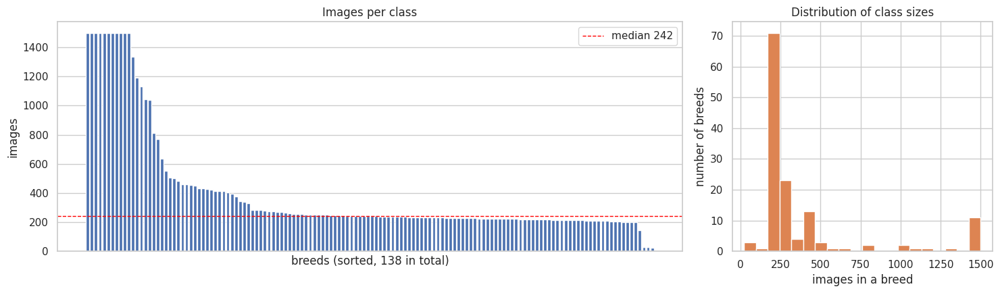

Most images: {'Teddy': 1500, 'Samoyed': 1500, 'Labrador Retriever': 1500, 'Miniature Schnauzer': 1500, 'Pomeranian': 1500}
Fewest images: {'Shiba Inu': 200, 'Mix': 146, 'Caucasian Ovcharka': 30, 'Dachshund': 30, 'Shiba': 23}


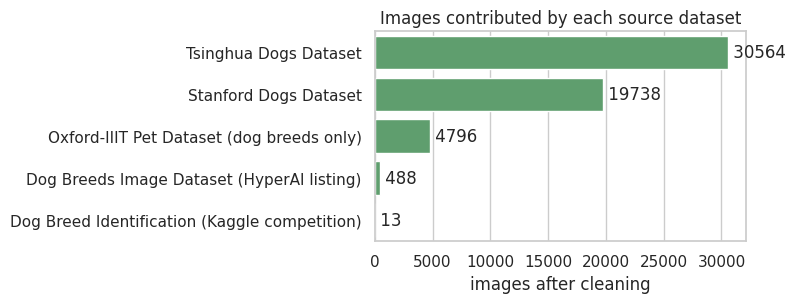

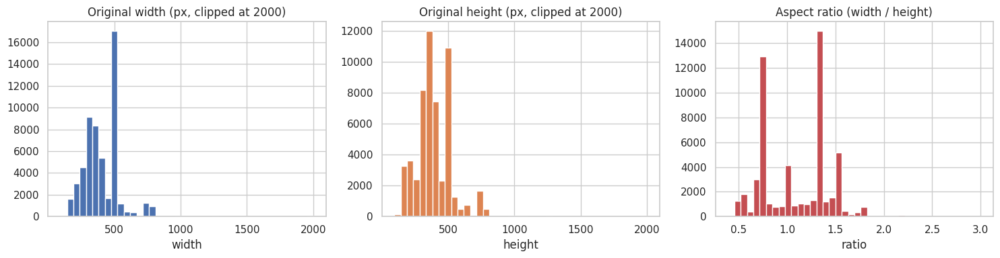

Original image sizes (55599 images measured): median 400 x 375, width 97-5184, height 96-4032. Sizes vary a lot, so every image is resized to 256x256 (stored) and 224x224 (network input).


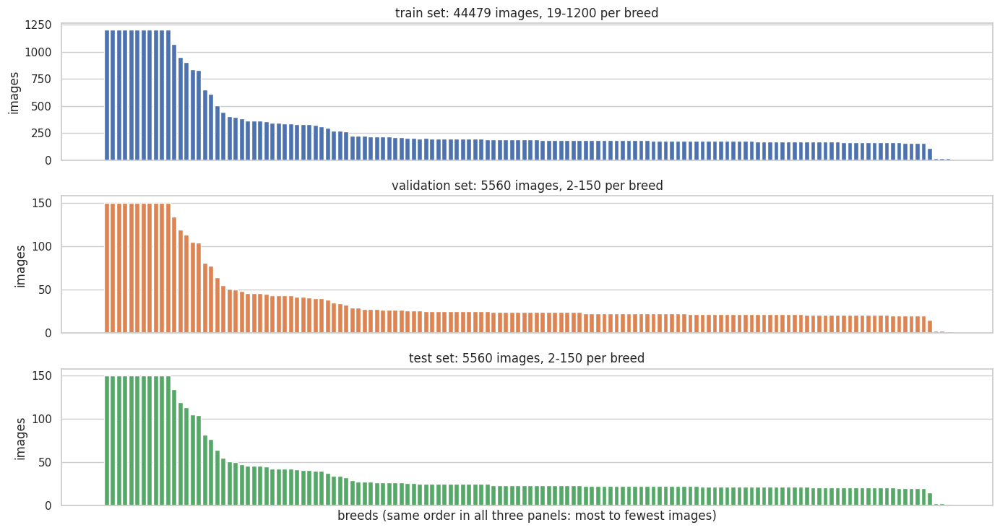

SPLIT: {'train': '44479 images (80%)', 'validation': '5560 images (10%)', 'test': '5560 images (10%)'} | largest difference between a breed's share in a split and in the whole data set: 0.0001 (stratified split)

BALANCE: the largest breed has 65.2x more images than the smallest (1500 vs 23), so the data set is imbalanced. 11 breeds hit the cap of 1500 images; 3 breeds have fewer than 100 images.
How imbalance is handled: (1) no breed may exceed the cap, so no breed dominates; (2) the split is stratified, so every breed appears in train, validation and test in the same proportion; (3) breeds with few images are kept because the pretrained network only has to learn a small head for them; (4) label smoothing and augmentation limit over-confidence on the large breeds; (5) macro-averaged precision/recall/F1 are reported, which give every breed equal weight, so poor results on small breeds are not hidden by the large ones.


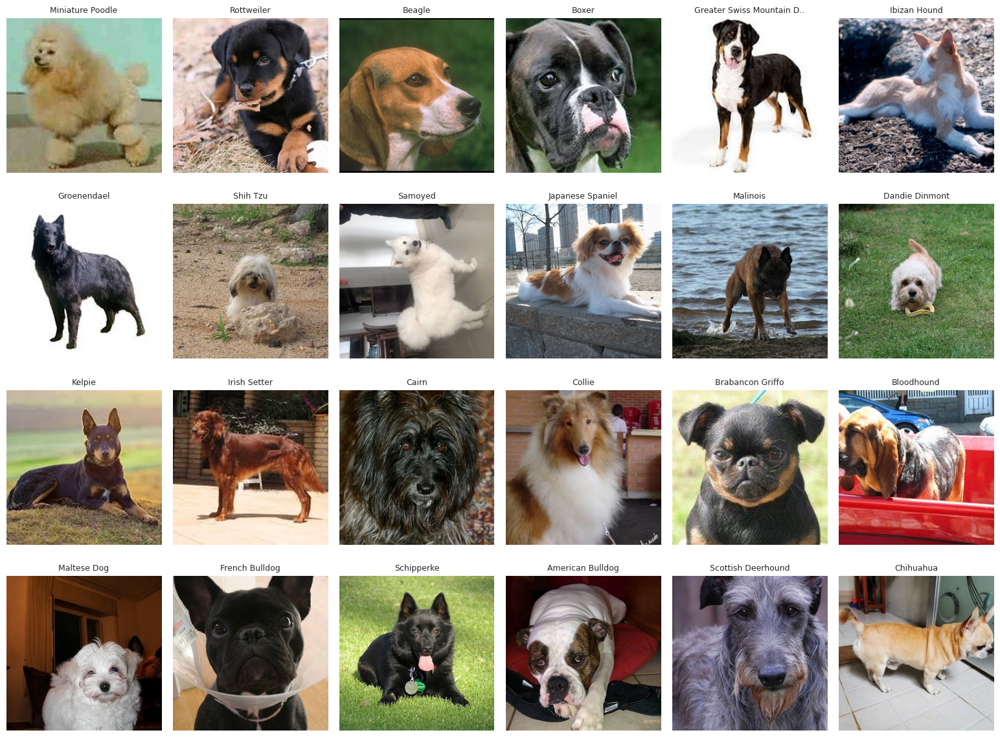

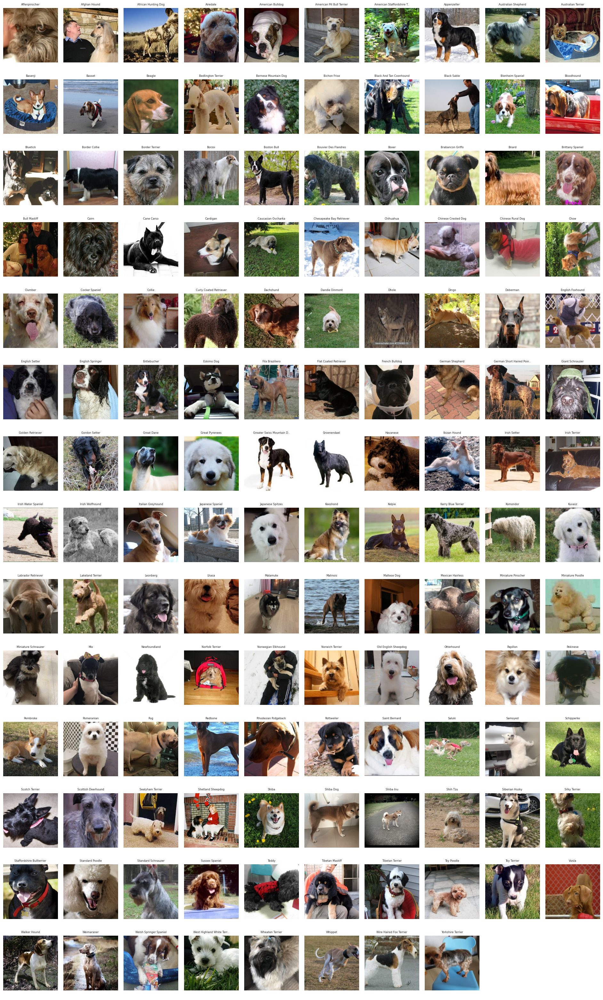

In [11]:
import seaborn as sns
sns.set_theme(style='whitegrid')

DATASET_INFO = {
    'stanford': dict(name='Stanford Dogs Dataset', url='http://vision.stanford.edu/aditya86/ImageNetDogs/', on_kaggle='no (downloaded from the Stanford site)',
                     note='120 breeds, 20,580 images, a subset of ImageNet (Khosla et al., 2011)'),
    'oxford': dict(name='Oxford-IIIT Pet Dataset (dog breeds only)', url='https://www.robots.ox.ac.uk/~vgg/data/pets/', on_kaggle='no (downloaded from the Oxford site)',
                   note='25 dog breeds of 37 pet breeds, about 200 images per breed (Parkhi et al., 2012)'),
    'tsinghua': dict(name='Tsinghua Dogs Dataset', url='https://cg.cs.tsinghua.edu.cn/ThuDogs/', on_kaggle='no (downloaded from the Tsinghua site)',
                     note='130 breeds, 70,428 images (Zou et al., 2020)'),
    'hyperai_dogbreeds': dict(name='Dog Breeds Image Dataset (HyperAI listing)', url='https://www.kaggle.com/datasets/darshanthakare/dog-breeds-image-dataset',
                              on_kaggle='yes', note='Kaggle dataset, downloaded with kagglehub'),
    'kaggle_breedid': dict(name='Dog Breed Identification (Kaggle competition)', url='https://www.kaggle.com/c/dog-breed-identification', on_kaggle='yes',
                           note='10,222 labelled training images of 120 breeds (a subset of Stanford Dogs / ImageNet)'),
    'wild': dict(name='Dogs-in-the-Wild (HyperAI)', url='https://hyper.ai/', on_kaggle='no', note='manual download'),
}
counts = df.breed.value_counts()
raw_by_source = pd.read_csv(INDEX).source.value_counts()
src_table = pd.DataFrame({'downloaded_and_readable': raw_by_source, 'after_cleaning': df.source.value_counts(),
                          'breeds': df.groupby('source').breed.nunique()}).fillna(0).astype(int).sort_values('after_cleaning', ascending=False)
src_table['dataset'] = [DATASET_INFO.get(s, {}).get('name', s) for s in src_table.index]
print('IMAGES PER SOURCE DATASET (images that were readable, and what is left after removing duplicates and conflicts)')
print(src_table[['dataset', 'downloaded_and_readable', 'after_cleaning', 'breeds']].to_string())

ratio = float(counts.max() / counts.min())
verdict = 'fairly balanced' if ratio <= 1.5 else ('mildly imbalanced' if ratio <= 5 else 'imbalanced')
n_capped = int((counts >= CFG['max_per_class']).sum())
EDA = dict(n_images=int(len(df)), n_classes=int(len(counts)), per_class_min=int(counts.min()), per_class_median=float(counts.median()),
           per_class_mean=float(counts.mean()), per_class_max=int(counts.max()), imbalance_ratio=ratio, verdict=verdict,
           n_capped=n_capped, n_under_100=int((counts < 100).sum()), n_under_60=int((counts < 60).sum()),
           most_images=counts.head(5).to_dict(), fewest_images=counts.tail(5).to_dict(),
           sources=src_table.reset_index().rename(columns={'index': 'source'}).to_dict('records'),
           clean=CLEAN_STATS, img_store=S, img_input=IMG)
print(f'\nSUMMARY: {EDA["n_images"]} images, {EDA["n_classes"]} classes. Images per class: min {EDA["per_class_min"]}, median {EDA["per_class_median"]:.0f}, '
      f'max {EDA["per_class_max"]} (max/min = {ratio:.1f}x). The data is {verdict}.')
print(f'Cleaning: {CLEAN_STATS["after_merge_images"]} images -> {CLEAN_STATS["duplicates_removed"]} duplicate copies removed, '
      f'{CLEAN_STATS["conflicts_removed"]} removed because the same photo had different breed labels, {CLEAN_STATS["breeds_dropped"]} breeds dropped for having too few images.')
if (ROOT / 'prep_stats.json').exists():
    ps = json.loads((ROOT / 'prep_stats.json').read_text())
    EDA['unreadable'] = ps['unreadable']; EDA['scanned'] = ps['scanned']
    print(f'Corrupt or unusable files (could not be decoded, or shorter side < 64 px): {ps["unreadable"]} of {ps["scanned"]} files, dropped automatically.')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2.4, 1]})
ordered = counts.sort_values(ascending=False)
ax[0].bar(range(len(ordered)), ordered.values, color=sns.color_palette('deep')[0])
ax[0].axhline(counts.median(), color='red', ls='--', lw=1, label=f'median {counts.median():.0f}')
ax[0].set_xlabel(f'breeds (sorted, {len(ordered)} in total)'); ax[0].set_ylabel('images'); ax[0].set_title('Images per class'); ax[0].legend()
ax[0].set_xticks([])
ax[1].hist(counts.values, bins=20, color=sns.color_palette('deep')[1]); ax[1].set_xlabel('images in a breed'); ax[1].set_ylabel('number of breeds'); ax[1].set_title('Distribution of class sizes')
plt.tight_layout(); savefig(fig, 'eda_images_per_class.png'); plt.show()
print('Most images:', counts.head(5).to_dict()); print('Fewest images:', counts.tail(5).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.barplot(y=src_table.dataset, x=src_table.after_cleaning, ax=ax, color=sns.color_palette('deep')[2])
ax.set_xlabel('images after cleaning'); ax.set_ylabel(''); ax.set_title('Images contributed by each source dataset')
for i, v in enumerate(src_table.after_cleaning):
    ax.text(v, i, f' {v}', va='center')
plt.tight_layout(); savefig(fig, 'eda_sources.png'); plt.show()

has = df[['w', 'h']].dropna()
if len(has) >= 200:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].hist(has.w.clip(upper=2000), bins=40, color=sns.color_palette('deep')[0]); ax[0].set_title('Original width (px, clipped at 2000)'); ax[0].set_xlabel('width')
    ax[1].hist(has.h.clip(upper=2000), bins=40, color=sns.color_palette('deep')[1]); ax[1].set_title('Original height (px, clipped at 2000)'); ax[1].set_xlabel('height')
    ar = (has.w / has.h).clip(0.3, 3)
    ax[2].hist(ar, bins=40, color=sns.color_palette('deep')[3]); ax[2].set_title('Aspect ratio (width / height)'); ax[2].set_xlabel('ratio')
    plt.tight_layout(); savefig(fig, 'eda_image_dimensions.png'); plt.show()
    EDA['dims'] = dict(n_measured=int(len(has)), w_median=float(has.w.median()), h_median=float(has.h.median()), w_min=int(has.w.min()), w_max=int(has.w.max()),
                       h_min=int(has.h.min()), h_max=int(has.h.max()), square_share=float(((ar > 0.95) & (ar < 1.05)).mean()),
                       landscape_share=float((ar >= 1.05).mean()))
    print(f'Original image sizes ({len(has)} images measured): median {has.w.median():.0f} x {has.h.median():.0f}, width {has.w.min():.0f}-{has.w.max():.0f}, '
          f'height {has.h.min():.0f}-{has.h.max():.0f}. Sizes vary a lot, so every image is resized to {S}x{S} (stored) and {IMG}x{IMG} (network input).')
else:
    print(f'Original image sizes were not recorded for this saved dataset (it was built by an older version). Every stored image is {S}x{S}; the network input is {IMG}x{IMG}.')

fig, ax = plt.subplots(3, 1, figsize=(14, 7.5), sharex=True)
order = list(counts.index)
SPLIT_TABLE = {}
for a, (nm, fr) in zip(ax, {'train': train_df, 'validation': val_df, 'test': test_df}.items()):
    c = fr.breed.value_counts().reindex(order).fillna(0)
    a.bar(range(len(order)), c.values, color=sns.color_palette('deep')[{'train': 0, 'validation': 1, 'test': 2}[nm]])
    a.set_ylabel('images'); a.set_title(f'{nm} set: {len(fr)} images, {int(c.min())}-{int(c.max())} per breed')
    SPLIT_TABLE[nm] = dict(images=int(len(fr)), share=float(len(fr) / len(df)), per_class_min=int(c.min()), per_class_max=int(c.max()))
ax[-1].set_xlabel('breeds (same order in all three panels: most to fewest images)'); ax[-1].set_xticks([])
plt.tight_layout(); savefig(fig, 'eda_split_distribution.png'); plt.show()
EDA['splits'] = SPLIT_TABLE
share_dev = max(abs(fr.breed.value_counts(normalize=True).reindex(order).fillna(0) - counts.reindex(order) / len(df)).max() for fr in (train_df, val_df, test_df))
EDA['split_max_share_deviation'] = float(share_dev)
print('SPLIT:', {k: f'{v["images"]} images ({v["share"]:.0%})' for k, v in SPLIT_TABLE.items()},
      f'| largest difference between a breed\'s share in a split and in the whole data set: {share_dev:.4f} (stratified split)')

print(f'\nBALANCE: the largest breed has {ratio:.1f}x more images than the smallest ({EDA["per_class_max"]} vs {EDA["per_class_min"]}), so the data set is {verdict}. '
      f'{n_capped} breeds hit the cap of {CFG["max_per_class"]} images; {EDA["n_under_100"]} breeds have fewer than 100 images.')
print('How imbalance is handled: (1) no breed may exceed the cap, so no breed dominates; (2) the split is stratified, so every breed appears in train, validation and test in the same proportion; '
      '(3) breeds with few images are kept because the pretrained network only has to learn a small head for them; (4) label smoothing and augmentation limit over-confidence on the large breeds; '
      '(5) macro-averaged precision/recall/F1 are reported, which give every breed equal weight, so poor results on small breeds are not hidden by the large ones.')

rs = np.random.RandomState(SEED)
pick = df.loc[[g.index[rs.randint(len(g))] for _, g in df.groupby('breed')]]
def grid(frame, ncols, cell, fname, fs):
    nrows = math.ceil(len(frame) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell, nrows * (cell + 0.35)))
    for a in np.ravel(axes):
        a.axis('off')
    for a, (_, r) in zip(np.ravel(axes), frame.iterrows()):
        a.imshow(Image.open(r.path)); a.set_title(r.breed if len(r.breed) < 26 else r.breed[:24] + '..', fontsize=fs)
    plt.tight_layout(); savefig(fig, fname, dpi=110); plt.show()
grid(pick.sample(n=min(24, len(pick)), random_state=SEED), 6, 2.6, 'sample_images.png', 9)
grid(pick, 10, 1.9, 'sample_images_all_classes.png', 6)
RESULTS['eda'] = EDA
save_results()

## 3. Preprocessing, augmentation and training pipeline

Images enter the networks as raw 0-255 pixels; each pretrained network's own scaling is applied inside the model. Augmentation (flip, rotation, zoom, shift, contrast) runs on the GPU during training only. Transfer learning has two phases: the new classifier is trained with the backbone frozen, then the top of the backbone is fine-tuned at a low learning rate (BatchNorm layers stay frozen).

ImageNet, which pretrained the backbones, contains the photos Stanford Dogs was built from, so scores on Stanford images are optimistic.

In [12]:
import tensorflow as tf
import keras
from keras import layers

gpus = tf.config.list_physical_devices('GPU')
print('GPUs:', gpus or 'NONE. Use Runtime > Change runtime type > T4 GPU; on CPU this will be very slow.')
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')
keras.utils.set_random_seed(SEED)


def fresh_session():
    keras.backend.clear_session()
    if gpus:
        keras.mixed_precision.set_global_policy('mixed_float16')


NC = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE


def make_ds(frame, training, batch):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.y.values.astype('int32')))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)

    def load(path, y):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        img.set_shape([S, S, 3])
        if training:
            img = tf.image.random_crop(img, [IMG, IMG, 3])
        else:
            off = (S - IMG) // 2
            img = tf.image.crop_to_bounding_box(img, off, off, IMG, IMG)
        return tf.cast(img, tf.float32), tf.one_hot(y, NC)

    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)


def augment_block(a):
    seq = [layers.RandomFlip('horizontal')]
    if a > 0:
        seq += [layers.RandomRotation(0.08 * a, fill_mode='reflect'),
                layers.RandomZoom(0.15 * a, fill_mode='reflect'),
                layers.RandomTranslation(0.08 * a, 0.08 * a, fill_mode='reflect'),
                layers.RandomContrast(0.2 * a)]
    return keras.Sequential(seq, name='augment')


PREPROCESS = {'MobileNet': 'tf', 'MobileNetV2': 'tf', 'InceptionV3': 'tf',
              'ResNet50': 'caffe', 'VGG16': 'caffe', 'VGG19': 'caffe',
              'EfficientNetB0': 'builtin', 'EfficientNetV2B0': 'builtin'}
CAFFE_MEAN_BGR = np.array([103.939, 116.779, 123.68], dtype='float32')


def preprocess(x, arch):
    mode = PREPROCESS[arch]
    if mode == 'tf':
        return layers.Rescaling(1 / 127.5, offset=-1, name='preprocess')(x)
    if mode == 'caffe':
        conv = layers.Conv2D(3, 1, trainable=False, name='preprocess')
        x = conv(x)
        W = np.zeros((1, 1, 3, 3), dtype='float32')
        W[0, 0, 2, 0] = W[0, 0, 1, 1] = W[0, 0, 0, 2] = 1.0
        conv.set_weights([W, -CAFFE_MEAN_BGR])
        return x
    return x


DEFAULT_HP = dict(dropout=0.3, dense=0, ls=0.1, lr_head=1e-3, lr_ft=5e-5, wd=1e-3, unfreeze=0.3, aug=0.5, batch=32)


def stratified_sample(frame, n, seed):
    if n >= len(frame):
        return frame
    return frame.groupby('breed', group_keys=False).sample(frac=n / len(frame), random_state=seed)


def score_from_hist(hist):
    va = np.array(hist['val_accuracy'])
    k = int(va.argmax())
    gap = float(hist['accuracy'][k] - va[k])
    return float(va[k] - 0.25 * max(0.0, gap - 0.10)), float(va[k]), gap, k


def build_model(hp):
    inp = keras.Input((IMG, IMG, 3))
    x = inp if hp.get('no_augment') else augment_block(hp['aug'])(inp)
    x = preprocess(x, hp['arch'])
    backbone = getattr(keras.applications, hp['arch'])(
        include_top=False, weights=CFG['pretrained'], input_shape=(IMG, IMG, 3), pooling='avg')
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.Dropout(hp['dropout'])(x)
    if hp['dense'] > 0:
        x = layers.Dense(hp['dense'], activation='relu')(x)
        x = layers.Dropout(hp['dropout'])(x)
    out = layers.Dense(NC, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out), backbone


def compile_model(model, lr, wd, ls):
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=ls),
        metrics=[keras.metrics.CategoricalAccuracy(name='accuracy'),
                 keras.metrics.TopKCategoricalAccuracy(k=5, name='top5')])


def unfreeze_top(backbone, frac):
    backbone.trainable = True
    n = len(backbone.layers)
    for l in backbone.layers[:n - int(n * frac)]:
        l.trainable = False
    for l in backbone.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False


def run_training(hp, train_ds, val_ds, epochs_head, epochs_ft, extra_cb=None, final=False, verbose=2):
    model, backbone = build_model(hp)
    hist = {}

    def merge(h):
        for k, v in h.history.items():
            hist.setdefault(k, []).extend(v)

    compile_model(model, hp['lr_head'], hp['wd'], hp['ls'])
    merge(model.fit(train_ds, validation_data=val_ds, epochs=epochs_head,
                    callbacks=[extra_cb(0)] if extra_cb else [], verbose=verbose))
    unfreeze_top(backbone, hp['unfreeze'])
    compile_model(model, hp['lr_ft'], hp['wd'], hp['ls'])
    cbs = [extra_cb(epochs_head)] if extra_cb else []
    if final:
        cbs += [keras.callbacks.EarlyStopping('val_loss', patience=4, restore_best_weights=True, verbose=1),
                keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1)]
    merge(model.fit(train_ds, validation_data=val_ds, epochs=epochs_ft, callbacks=cbs, verbose=verbose))
    return model, hist

HAVE_SAVED_MODEL = False
if PERSIST and not CFG['retrain'] and (PERSIST / 'dog_breed_model.keras').exists() and (PERSIST / 'class_names.json').exists():
    HAVE_SAVED_MODEL = json.loads((PERSIST / 'class_names.json').read_text()) == class_names
    print('Trained model found on Drive.' if HAVE_SAVED_MODEL else 'A saved model exists but was trained on different breeds, so a new one will be trained.')

GPUs: NONE. Use Runtime > Change runtime type > T4 GPU; on CPU this will be very slow.
Trained model found on Drive.


### Preprocessing steps

| Step | What is done | Why |
|---|---|---|
| Loading, corrupt files | EXIF rotation applied, converted to RGB; unreadable files and images under 64 px are dropped. | One unreadable file would stop training; tiny images cannot show a breed. |
| Resizing | Short side to 256 px, centre crop 256x256. Training uses a random 224x224 crop, validation and test the centre crop. | Fixed input size; scaling the short side avoids stretching the dog. |
| Normalisation | Each pretrained network's own pixel scaling is part of the model (e.g. 0-255 to [-1, 1]); the custom CNN divides by 255. | Stable training and input that matches the pretrained weights. |
| Label encoding | Breeds are indexed alphabetically and one-hot encoded. | Needed by softmax and categorical cross-entropy. |
| Split | 80 / 10 / 10 %, stratified by breed, after duplicate removal. | Every breed appears in each set; no leakage. |
| Augmentation | Horizontal flip, small rotation, zoom, shift, contrast, random crop; training only. | The same breed looks different from other angles, distances and light, so augmentation reduces overfitting. Vertical flips and strong colour changes are avoided because they distort coat colour and pose. |
| Batches | `tf.data` pipeline: parallel decoding, shuffling, batches of 32-64, prefetching. | The data is larger than GPU memory. |

LABEL ENCODING (first 8 of 138 classes):
 index                          breed
     0                  Affenpinscher
     1                   Afghan Hound
     2            African Hunting Dog
     3                       Airedale
     4               American Bulldog
     5      American Pit Bull Terrier
     6 American Staffordshire Terrier
     7                    Appenzeller

Example: "Airedale" -> index 3 -> one-hot vector with a 1 at position 3 and 137 zeros

Stored image (256, 256) -> 224x224 crop. Pixel range before normalisation: 7-255, mean 143.5
After scaling to [-1, 1] (as MobileNet / InceptionV3 expect): range -0.95-1.00, mean 0.125


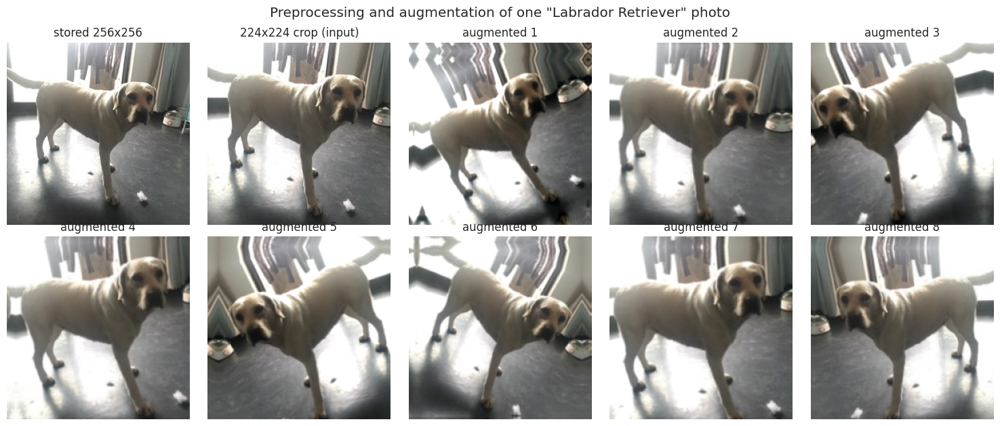


Batch generation: one training batch has images (32, 224, 224, 3) (batch, height, width, channels) and labels (32, 138) (batch, classes)


In [13]:
enc = pd.DataFrame({'index': range(len(class_names)), 'breed': class_names})
print('LABEL ENCODING (first 8 of', len(class_names), 'classes):')
print(enc.head(8).to_string(index=False))
ex = 3
print(f'\nExample: "{class_names[ex]}" -> index {ex} -> one-hot vector with a 1 at position {ex} and {len(class_names) - 1} zeros')

row = train_df.iloc[0]
with Image.open(row.path) as im0:
    stored = im0.convert('RGB')
crop = stored.crop(((S - IMG) // 2, (S - IMG) // 2, (S - IMG) // 2 + IMG, (S - IMG) // 2 + IMG))
arr = np.asarray(crop, dtype=np.float32)
print(f'\nStored image {stored.size} -> {IMG}x{IMG} crop. Pixel range before normalisation: {arr.min():.0f}-{arr.max():.0f}, mean {arr.mean():.1f}')
scaled = arr / 127.5 - 1
print(f'After scaling to [-1, 1] (as MobileNet / InceptionV3 expect): range {scaled.min():.2f}-{scaled.max():.2f}, mean {scaled.mean():.3f}')

aug = augment_block(1.0)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
axes[0, 0].imshow(stored); axes[0, 0].set_title(f'stored {S}x{S}'); axes[0, 1].imshow(crop); axes[0, 1].set_title(f'{IMG}x{IMG} crop (input)')
x4 = np.repeat(arr[None], 8, axis=0)
out = np.clip(aug(x4, training=True).numpy(), 0, 255).astype('uint8')
for k, a in enumerate(list(axes[0, 2:]) + list(axes[1])):
    a.imshow(out[k]); a.set_title(f'augmented {k + 1}')
for a in axes.ravel():
    a.axis('off')
plt.suptitle(f'Preprocessing and augmentation of one "{row.breed}" photo'); plt.tight_layout(); savefig(fig, 'preprocessing_augmentation.png'); plt.show()

b_x, b_y = next(iter(make_ds(train_df, True, 32)))
print(f'\nBatch generation: one training batch has images {tuple(b_x.shape)} (batch, height, width, channels) and labels {tuple(b_y.shape)} (batch, classes)')
RESULTS['preprocessing'] = dict(batch_images=list(map(int, b_x.shape)), batch_labels=list(map(int, b_y.shape)))
save_results()

## 4. Custom CNN (built from scratch)

`Input -> Resize 128x128 -> augmentation -> /255 -> 4 x ([Conv3x3 + BatchNorm + ReLU] x2 + MaxPool) with 32, 64, 128, 256 filters -> Global Average Pooling -> Dense 512 -> Dropout 0.5 -> Softmax`

Adam (learning rate 1e-3), categorical cross-entropy, batch size 64, early stopping (patience 6), ReduceLROnPlateau and model checkpointing.

Model: "custom_cnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize (Resizing)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼─────────────────────

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 58 variables whereas the saved optimizer has 62 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


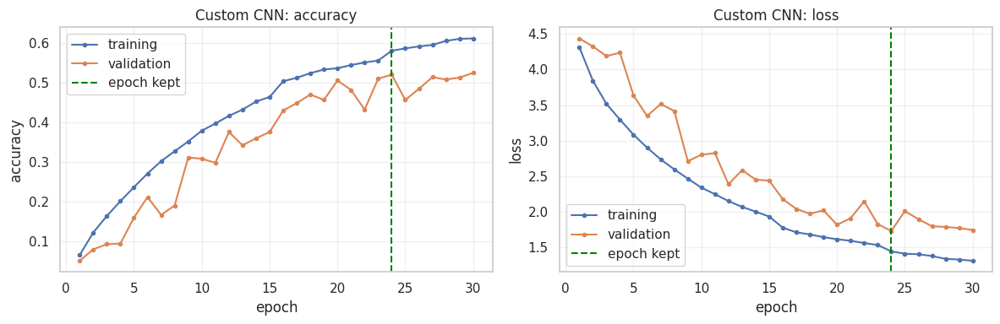


Custom CNN: 30 epochs in 54.7 min, 1.38 M parameters.
At the kept epoch (24): train acc 0.580, val acc 0.520, train loss 1.445, val loss 1.733
Test (never seen): accuracy 0.526, macro precision 0.482, macro recall 0.436, macro F1 0.435, top-5 0.834
Diagnosis: WELL FITTED - Training accuracy (58.0%) and validation accuracy (52.0%) are close (gap +6.0%) and both are high or still improving, so the model is well fitted. (Training accuracy is measured with augmentation and dropout switched on, which is why it can sit slightly below validation.)


In [14]:
def build_custom_cnn(img=None, dropout=0.5):
    img = img or CFG['cnn_img']
    inp = keras.Input((IMG, IMG, 3), name='image')
    x = layers.Resizing(img, img, name='resize')(inp)
    x = augment_block(0.5)(x)
    x = layers.Rescaling(1 / 255.0, name='rescale')(x)
    for f in (32, 64, 128, 256):
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NC, activation='softmax', dtype='float32')(x)
    return keras.Model(inp, out, name='custom_cnn')


CNN_FILE = ROOT / 'cnn_model.keras'
if PERSIST and (PERSIST / 'cnn_model.keras').exists() and not CNN_FILE.exists():
    shutil.copy(PERSIST / 'cnn_model.keras', CNN_FILE)

fresh_session()
cnn = build_custom_cnn()
lines = []
cnn.summary(print_fn=lines.append)
(RES / 'cnn_summary.txt').write_text('\n'.join(lines))
def _shape(l):
    try:
        return str(tuple(l.output.shape))
    except Exception:
        return ''


CNN_LAYERS = [dict(name=l.name, type=type(l).__name__, output=_shape(l), params=int(l.count_params())) for l in cnn.layers]
RESULTS['cnn_layers'] = CNN_LAYERS
print('\n'.join(lines))

if RESULTS.get('cnn') and CNN_FILE.exists() and not CFG['retrain']:
    print('\nThe custom CNN was already trained (results restored from Drive). Set retrain=True in the config to train it again.')
    cnn = keras.models.load_model(CNN_FILE)
else:
    cnn_train, cnn_val = make_ds(train_df, True, 64), make_ds(val_df, False, 64)
    cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy',
                metrics=[keras.metrics.CategoricalAccuracy(name='accuracy'), keras.metrics.TopKCategoricalAccuracy(k=5, name='top5')])
    cbs = [keras.callbacks.EarlyStopping('val_loss', patience=6, restore_best_weights=True, verbose=1),
           keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
           keras.callbacks.ModelCheckpoint(str(ROOT / 'cnn_best_checkpoint.keras'), monitor='val_loss', save_best_only=True)]
    t0 = time.time()
    h = cnn.fit(cnn_train, validation_data=cnn_val, epochs=CFG['cnn_epochs'], callbacks=cbs, verbose=2)
    cnn_minutes = (time.time() - t0) / 60
    cnn_hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best_ep = int(np.argmin(cnn_hist['val_loss']))
    probs_cnn = cnn.predict(make_ds(test_df, False, 64), verbose=0)
    met = metrics_from_probs(test_df.y.values, probs_cnn)
    diag = fit_diagnosis(cnn_hist, best_ep)
    RESULTS['cnn'] = dict(met, params=int(cnn.count_params()), minutes=cnn_minutes, epochs_run=len(cnn_hist['loss']), best_epoch=best_ep + 1,
                          max_epochs=CFG['cnn_epochs'], history=cnn_hist, diagnosis=diag, batch=64, lr=1e-3, optimizer='Adam', loss='categorical cross-entropy',
                          dropout=0.5, input=CFG['cnn_img'], train_acc=cnn_hist['accuracy'][best_ep], val_acc=cnn_hist['val_accuracy'][best_ep],
                          train_loss=cnn_hist['loss'][best_ep], val_loss=cnn_hist['val_loss'][best_ep])
    cnn.save(CNN_FILE)
    if PERSIST:
        shutil.copy(CNN_FILE, PERSIST / 'cnn_model.keras')
    save_results()

r = RESULTS['cnn']
plot_history(r['history'], 'Custom CNN', 'cnn_', best_ep=r['best_epoch'] - 1)
print(f'\nCustom CNN: {r["epochs_run"]} epochs in {r["minutes"]:.1f} min, {r["params"] / 1e6:.2f} M parameters.')
print(f'At the kept epoch ({r["best_epoch"]}): train acc {r["train_acc"]:.3f}, val acc {r["val_acc"]:.3f}, train loss {r["train_loss"]:.3f}, val loss {r["val_loss"]:.3f}')
print(f'Test (never seen): accuracy {r["accuracy"]:.3f}, macro precision {r["precision_macro"]:.3f}, macro recall {r["recall_macro"]:.3f}, macro F1 {r["f1_macro"]:.3f}, top-5 {r["top5"]:.3f}')
print('Diagnosis:', r['diagnosis']['label'].upper(), '-', r['diagnosis']['text'])

## 5. Transfer learning

### 5.1 Architecture comparison

Eight pretrained networks (MobileNet, MobileNetV2, ResNet50, VGG16, VGG19, InceptionV3, EfficientNetB0, EfficientNetV2B0) get the same short training run on the same data. They are scored on validation data, with a penalty when training accuracy runs well ahead of validation accuracy.

In [15]:
if HAVE_SAVED_MODEL:
    print('A trained model for these breeds is already on Drive: skipping the architecture comparison.')
else:
    cmp_train = stratified_sample(train_df, CFG['compare_train_images'], SEED)
    cmp_val = stratified_sample(val_df, CFG['compare_val_images'], SEED)
    print(f'Comparing {len(CFG["compare_archs"])} architectures on {len(cmp_train)} train / {len(cmp_val)} val images')

    board_file = ROOT / 'arch_leaderboard.csv'
    if PERSIST and (PERSIST / 'arch_leaderboard.csv').exists() and not board_file.exists():
        shutil.copy(PERSIST / 'arch_leaderboard.csv', board_file)
    rows = [r for r in pd.read_csv(board_file).to_dict('records') if r.get('n_classes') == NC] if board_file.exists() else []
    done = {r['arch'] for r in rows}
    n_epochs = CFG['compare_epochs_head'] + CFG['compare_epochs_ft']

    for arch in CFG['compare_archs']:
        if arch in done:
            print(f'{arch}: already done (loaded from the saved leaderboard)')
            continue
        fresh_session()
        hp = dict(DEFAULT_HP, arch=arch)
        tr, va = make_ds(cmp_train, True, hp['batch']), make_ds(cmp_val, False, 64)
        t0 = time.time()
        try:
            m, hist = run_training(hp, tr, va, CFG['compare_epochs_head'], CFG['compare_epochs_ft'], verbose=0)
        except Exception as e:
            print(f'!! {arch} failed and is skipped: {str(e)[:200]}')
            continue
        secs = time.time() - t0
        score, va_acc, gap, k = score_from_hist(hist)
        rows.append(dict(arch=arch, n_classes=NC, score=round(score, 4), val_top1=round(va_acc, 4), val_top5=round(float(hist['val_top5'][k]), 4),
                         train_val_gap=round(gap, 4), params_m=round(m.count_params() / 1e6, 1), minutes=round(secs / 60, 1),
                         imgs_per_s=int(len(cmp_train) * n_epochs / secs)))
        print(f'{arch}: val top-1 {va_acc:.3f}, gap {gap:+.3f}, {secs / 60:.1f} min')
        del m
        gc.collect()
        pd.DataFrame(rows).to_csv(board_file, index=False)
        if PERSIST:
            shutil.copy(board_file, PERSIST / 'arch_leaderboard.csv')

    board = pd.DataFrame(rows)
    board = board[board.arch.isin(CFG['compare_archs'])].sort_values('score', ascending=False).reset_index(drop=True)
    print('\nLeaderboard (score = val top-1 minus an overfitting penalty):')
    print(board.to_string())
    plt.figure(figsize=(8, 0.5 * len(board) + 1))
    plt.barh(board.arch[::-1], board.val_top1[::-1])
    plt.xlabel('validation top-1 (subset, short run)'); plt.xlim(max(0, board.val_top1.min() - 0.1), min(1, board.val_top1.max() + 0.05))
    plt.tight_layout(); plt.show()
    top_archs = board.arch.head(CFG['tune_top_k']).tolist()
    print('\nGoing on to tuning:', top_archs)

A trained model for these breeds is already on Drive: skipping the architecture comparison.


### 5.2 Hyperparameter tuning (Optuna)

The best network is tuned on data subsets and scored on validation data, never the test set, with the same overfitting penalty. Searched: dropout, extra dense layer, label smoothing, learning rates, weight decay, unfrozen fraction, augmentation strength and batch size. Progress is saved after every trial.

In [16]:
if HAVE_SAVED_MODEL:
    print('A trained model for these breeds is already on Drive: skipping tuning.')
else:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    tune_train = stratified_sample(train_df, CFG['tune_train_images'], SEED)
    tune_val = stratified_sample(val_df, CFG['tune_val_images'], SEED)
    print(f'Tuning {top_archs} on {len(tune_train)} train / {len(tune_val)} val images')


    class PruneCB(keras.callbacks.Callback):
        def __init__(self, trial, offset):
            super().__init__()
            self.trial, self.offset = trial, offset

        def on_epoch_end(self, epoch, logs=None):
            self.trial.report(float(logs['val_accuracy']), self.offset + epoch)
            if self.trial.should_prune():
                raise optuna.TrialPruned()


    def make_objective(arch):
        def objective(trial):
            hp = dict(
                arch=arch,
                dropout=trial.suggest_float('dropout', 0.2, 0.6),
                dense=trial.suggest_categorical('dense', [0, 512]),
                ls=trial.suggest_float('ls', 0.0, 0.2),
                lr_head=trial.suggest_float('lr_head', 3e-4, 3e-3, log=True),
                lr_ft=trial.suggest_float('lr_ft', 1e-5, 3e-4, log=True),
                wd=trial.suggest_float('wd', 1e-4, 5e-2, log=True),
                unfreeze=trial.suggest_float('unfreeze', 0.2, 1.0),
                aug=trial.suggest_float('aug', 0.0, 1.0),
                batch=trial.suggest_categorical('batch', [16, 32, 64]),
            )
            fresh_session()
            tr, va = make_ds(tune_train, True, hp['batch']), make_ds(tune_val, False, 64)
            try:
                model, hist = run_training(hp, tr, va, CFG['tune_epochs_head'], CFG['tune_epochs_ft'],
                                           extra_cb=lambda off: PruneCB(trial, off), verbose=0)
            except optuna.TrialPruned:
                raise
            except Exception as e:
                print(f'trial {trial.number} ({arch}) failed, skipped: {str(e)[:120]}')
                gc.collect()
                raise optuna.TrialPruned()
            score, va_acc, gap, k = score_from_hist(hist)
            trial.set_user_attr('val_acc', va_acc)
            trial.set_user_attr('train_val_gap', gap)
            del model
            gc.collect()
            return score
        return objective


    db = ROOT / 'optuna.db'
    if PERSIST and (PERSIST / 'optuna.db').exists() and not db.exists():
        shutil.copy(PERSIST / 'optuna.db', db)


    def backup(study, trial):
        if PERSIST:
            shutil.copy(db, PERSIST / 'optuna.db')


    results = []
    for arch in top_archs:
        study = optuna.create_study(
            study_name=f'dog_{arch}_{NC}classes', storage=f'sqlite:///{db}', load_if_exists=True, direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1))
        done = sum(t.state.name in ('COMPLETE', 'PRUNED') for t in study.trials)
        t0 = time.time()
        study.optimize(make_objective(arch), n_trials=max(0, CFG['tune_trials'] - done), callbacks=[backup])
        print(f'{arch}: tuning took {(time.time() - t0) / 60:.1f} min, best score {study.best_value:.4f}')
        results.append((study.best_value, arch, dict(study.best_trial.params), study))

    best_value, best_arch, best_params, best_study = max(results, key=lambda r: r[0])
    best_hp = dict(best_params, arch=best_arch)
    print(f'\nBest architecture after tuning: {best_arch} (score {best_value:.4f})')
    print('Best hyperparameters:', json.dumps(best_hp, indent=2))
    tdf = best_study.trials_dataframe()
    cols = ['number', 'value', 'state'] + [c for c in tdf.columns if c.startswith('params_') or c.startswith('user_attrs_')]
    print(tdf[cols].sort_values('value', ascending=False).head(8).round(4).to_string())
    imp = {}
    try:
        imp = {k: round(v, 3) for k, v in optuna.importance.get_param_importances(best_study).items()}
        print('\nParameter importance:', imp)
    except Exception:
        pass
    n_by_state = Counter(t.state.name for t in best_study.trials)
    TUNE_SUMMARY = dict(arch=best_arch, best_score=float(best_value), trials=dict(n_by_state), importance=imp, best_params=best_hp,
                        searched=['dropout', 'dense', 'ls', 'lr_head', 'lr_ft', 'wd', 'unfreeze', 'aug', 'batch'])
    (ROOT / 'tune_summary.json').write_text(json.dumps(TUNE_SUMMARY, indent=2, default=float))
    if PERSIST:
        shutil.copy(ROOT / 'tune_summary.json', PERSIST / 'tune_summary.json')

A trained model for these breeds is already on Drive: skipping tuning.


### 5.3 Final training

Trained on the full training set with early stopping on validation loss (best weights restored) and learning-rate reduction on plateau.

In [17]:
model, hist, FINAL_INFO = None, None, None
if HAVE_SAVED_MODEL:
    print('Loading the trained model from Drive instead of training again (set retrain=True in the config to train from scratch).')
    model = keras.models.load_model(PERSIST / 'dog_breed_model.keras')
    if (PERSIST / 'best_hp.json').exists():
        best_hp = json.loads((PERSIST / 'best_hp.json').read_text())
    if (PERSIST / 'final_info.json').exists():
        FINAL_INFO = json.loads((PERSIST / 'final_info.json').read_text())
        hist = FINAL_INFO['history']
else:
    print('Final training with', best_hp['arch'])
    fresh_session()
    tr_ds = make_ds(train_df, True, best_hp['batch'])
    va_ds = make_ds(val_df, False, 64)
    t_final = time.time()
    model, hist = run_training(best_hp, tr_ds, va_ds, CFG['final_epochs_head'], CFG['final_epochs_ft'], final=True, verbose=2)
    FINAL_MINUTES = (time.time() - t_final) / 60

    head = CFG['final_epochs_head']
    best_ep = head + int(np.argmin(hist['val_loss'][head:]))
    tr_acc, va_acc = hist['accuracy'][best_ep], hist['val_accuracy'][best_ep]
    print(f'\nKept weights from epoch {best_ep + 1}: train acc {tr_acc:.3f} | val acc {va_acc:.3f} | top-5 val {hist["val_top5"][best_ep]:.3f}')
    gap = tr_acc - va_acc
    print(f'Train-val gap: {gap:+.3f}  ->', 'looks healthy.' if gap < 0.10 else 'WARNING: sizeable gap. Rerun with a stronger regulariser (more dropout / augmentation / weight decay).')

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ['accuracy', 'loss']):
        a.plot(hist[m], label='train (with augmentation)'); a.plot(hist['val_' + m], label='validation')
        a.axvline(head - 0.5, color='gray', ls=':'); a.axvline(best_ep, color='green', ls='--', label='kept epoch')
        a.set_title(m); a.set_xlabel('epoch'); a.legend()
    plt.tight_layout(); plt.show()
    FINAL_INFO = dict(history=hist, minutes=FINAL_MINUTES, best_epoch=best_ep, head_epochs=head, params=int(model.count_params()), arch=best_hp['arch'])
    (ROOT / 'final_info.json').write_text(json.dumps(FINAL_INFO, default=float))
    if PERSIST:
        shutil.copy(ROOT / 'final_info.json', PERSIST / 'final_info.json')

Loading the trained model from Drive instead of training again (set retrain=True in the config to train from scratch).


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 90 variables whereas the saved optimizer has 94 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


### 5.4 Training curves of the final model

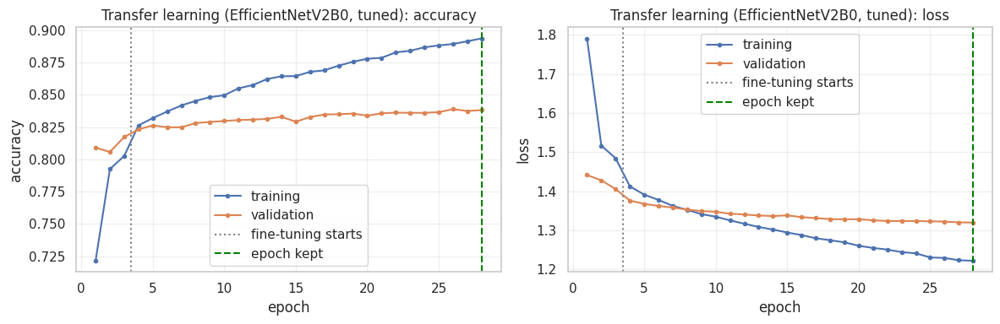

Diagnosis: WELL FITTED - Training accuracy (89.4%) and validation accuracy (83.8%) are close (gap +5.5%) and both are high or still improving, so the model is well fitted. (Training accuracy is measured with augmentation and dropout switched on, which is why it can sit slightly below validation.)


In [18]:
if hist is None:
    print('The training history of this model is not available (the model on Drive was trained before histories were saved).\n'
          'Set retrain=True in the config and run again if you need the curves for the report.')
else:
    head = FINAL_INFO['head_epochs'] if FINAL_INFO else CFG['final_epochs_head']
    kept = FINAL_INFO['best_epoch'] if FINAL_INFO else head + int(np.argmin(hist['val_loss'][head:]))
    plot_history(hist, f'Transfer learning ({best_hp["arch"]}, tuned)', '', head=head, best_ep=kept)
    d = fit_diagnosis(hist, kept)
    print('Diagnosis:', d['label'].upper(), '-', d['text'])
    TUNED_TRAIN = dict(history=hist, diagnosis=d, best_epoch=kept + 1, head_epochs=head, epochs_run=len(hist['loss']),
                       train_acc=hist['accuracy'][kept], val_acc=hist['val_accuracy'][kept], train_loss=hist['loss'][kept], val_loss=hist['val_loss'][kept])

### 5.5 Transfer learning before optimisation

The same network with default settings (no tuning, fixed number of epochs, no early stopping), to show what the optimisation steps add.

In [19]:
if RESULTS.get('transfer_default') and RESULTS['transfer_default'].get('arch') == best_hp['arch'] and not CFG['retrain']:
    print('The untuned transfer-learning model was already trained (results restored from Drive).')
else:
    arch = best_hp['arch']
    hp0 = dict(DEFAULT_HP, arch=arch)
    print(f'Training {arch} with default settings: {hp0}')
    tr0, va0 = make_ds(train_df, True, hp0['batch']), make_ds(val_df, False, 64)
    t0 = time.time()
    m0, h0 = run_training(hp0, tr0, va0, CFG['baseline_epochs_head'], CFG['baseline_epochs_ft'], final=False, verbose=2)
    minutes0 = (time.time() - t0) / 60
    h0 = {k: [float(v) for v in vals] for k, vals in h0.items()}
    probs0 = m0.predict(make_ds(test_df, False, 64), verbose=0)
    met0 = metrics_from_probs(test_df.y.values, probs0)
    k0 = int(np.argmax(h0['val_accuracy']))
    RESULTS['transfer_default'] = dict(met0, arch=arch, params=int(m0.count_params()), minutes=minutes0, epochs_run=len(h0['loss']), history=h0, hp=hp0,
                                       diagnosis=fit_diagnosis(h0, k0), train_acc=h0['accuracy'][k0], val_acc=h0['val_accuracy'][k0])
    del m0
    gc.collect()
    save_results()
r0 = RESULTS['transfer_default']
print(f'\nUntuned {r0["arch"]}: {r0["epochs_run"]} epochs, {r0["minutes"]:.1f} min. Test accuracy {r0["accuracy"]:.3f}, macro precision {r0["precision_macro"]:.3f}, '
      f'macro recall {r0["recall_macro"]:.3f}, macro F1 {r0["f1_macro"]:.3f}')
print('Diagnosis:', r0['diagnosis']['label'].upper(), '-', r0['diagnosis']['text'])

The untuned transfer-learning model was already trained (results restored from Drive).

Untuned EfficientNetV2B0: 8 epochs, 15.8 min. Test accuracy 0.839, macro precision 0.849, macro recall 0.837, macro F1 0.837
Diagnosis: WELL FITTED - Training accuracy (84.0%) and validation accuracy (82.8%) are close (gap +1.2%) and both are high or still improving, so the model is well fitted. (Training accuracy is measured with augmentation and dropout switched on, which is why it can sit slightly below validation.)


## 6. Evaluation on the test set

The test set was not used for tuning or early stopping.

In [20]:
from sklearn.metrics import f1_score
te_ds = make_ds(test_df, False, 64)
probs = model.predict(te_ds, verbose=0)
y_true = test_df.y.values
pred = probs.argmax(1)
top5 = np.argsort(-probs, axis=1)[:, :5]
print(f'Test top-1 accuracy: {(pred == y_true).mean():.4f}')
print(f'Test top-5 accuracy: {np.mean([y in t for y, t in zip(y_true, top5)]):.4f}')
print(f'Test macro-F1:       {f1_score(y_true, pred, average="macro"):.4f}')
from sklearn.metrics import precision_recall_fscore_support
mp, mr, _, _ = precision_recall_fscore_support(y_true, pred, average='macro', zero_division=0)
print(f'Test macro-precision: {mp:.4f}   (of the photos called breed X, how many really are X, averaged over breeds)')
print(f'Test macro-recall:    {mr:.4f}   (of the photos that really are breed X, how many were found, averaged over breeds)')
pb, rb, fb, nb_ = precision_recall_fscore_support(y_true, pred, labels=list(range(NC)), zero_division=0)
per_breed_metrics = pd.DataFrame({'breed': class_names, 'precision': pb, 'recall': rb, 'f1': fb, 'test_images': nb_}).sort_values('f1')
per_breed_metrics.to_csv(ROOT / 'per_breed_metrics.csv', index=False)
if PERSIST:
    shutil.copy(ROOT / 'per_breed_metrics.csv', PERSIST / 'per_breed_metrics.csv')
reliable = per_breed_metrics[per_breed_metrics.test_images >= 5]
print(f'\nBreeds with >= 5 test images ({len(reliable)} of {NC}): macro-precision {reliable.precision.mean():.3f}, macro-recall {reliable.recall.mean():.3f}   (breeds with fewer test photos give very noisy numbers)')
print('\nWeakest 10 breeds (full table saved as per_breed_metrics.csv):')
print(per_breed_metrics.head(10).round(3).to_string(index=False))

res = test_df.assign(correct=(pred == y_true), pred=[class_names[i] for i in pred], conf=probs.max(1))
print('\nAccuracy by source dataset:')
print(res.groupby('source').correct.agg(['mean', 'size']).rename(columns={'mean': 'accuracy', 'size': 'images'}).round(3).to_string())

per_breed = res.groupby('breed').correct.agg(['mean', 'size']).sort_values('mean')
print('\n15 hardest breeds:')
print(per_breed.head(15).round(3).to_string())

wrong = res[~res.correct]
print('\nMost common mix-ups (true -> predicted):')
for (t, p), n in Counter(zip(wrong.breed, wrong.pred)).most_common(10):
    print(f'  {t} -> {p}: {n}')

print('\nIf you only trust predictions above a confidence threshold:')
for thr in (0.3, 0.5, 0.7, 0.9):
    m = res.conf >= thr
    print(f'  conf >= {thr}: answers {m.mean():.1%} of photos, accuracy on those {res.correct[m].mean():.3f}')

Test top-1 accuracy: 0.8417
Test top-5 accuracy: 0.9797
Test macro-F1:       0.8380
Test macro-precision: 0.8500   (of the photos called breed X, how many really are X, averaged over breeds)
Test macro-recall:    0.8367   (of the photos that really are breed X, how many were found, averaged over breeds)

Breeds with >= 5 test images (135 of 138): macro-precision 0.854, macro-recall 0.845   (breeds with fewer test photos give very noisy numbers)

Weakest 10 breeds (full table saved as per_breed_metrics.csv):
                         breed  precision  recall    f1  test_images
                         Shiba      0.000   0.000 0.000            2
              Japanese Spitzes      0.556   0.200 0.294           25
                           Mix      0.800   0.267 0.400           15
     American Pit Bull Terrier      0.474   0.450 0.462           20
American Staffordshire Terrier      0.476   0.455 0.465           22
                     Dachshund      1.000   0.333 0.500            3
    

### 6.1 Confusion matrix and classification report

Precision: of the photos called a breed, how many are that breed. Recall: of the photos of a breed, how many were found. F1 is their harmonic mean. Macro averages weight every breed equally.

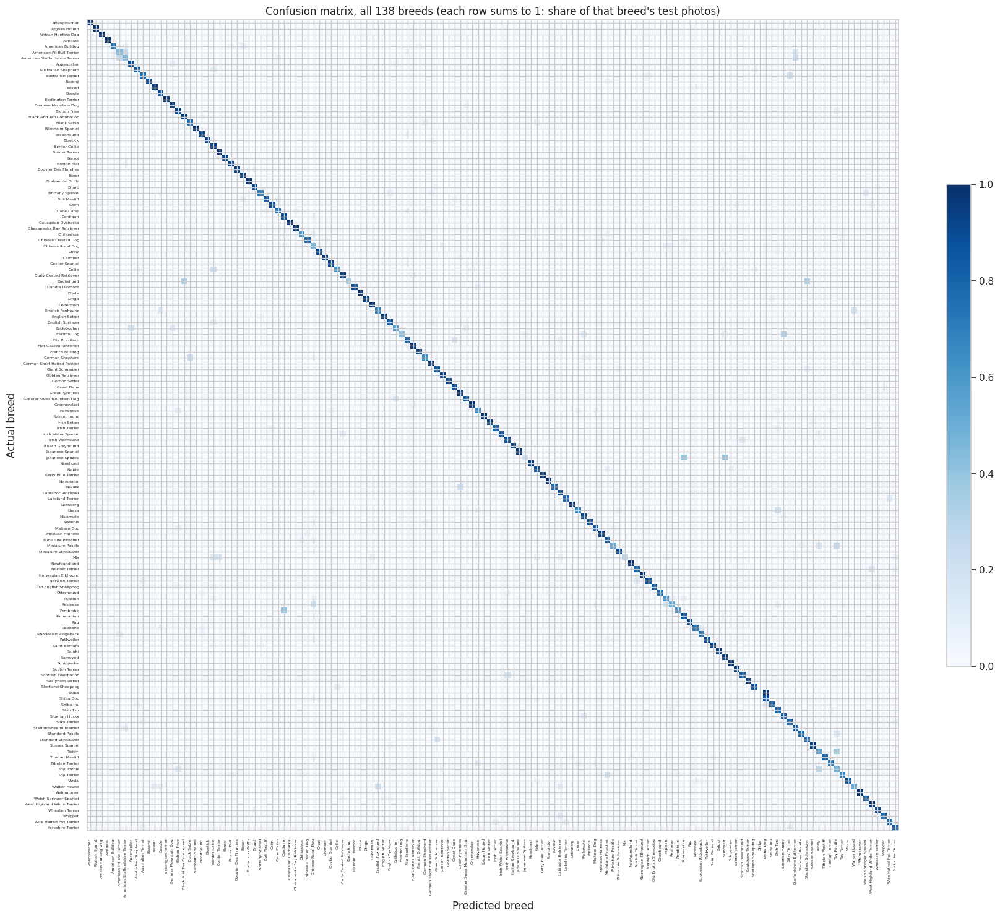

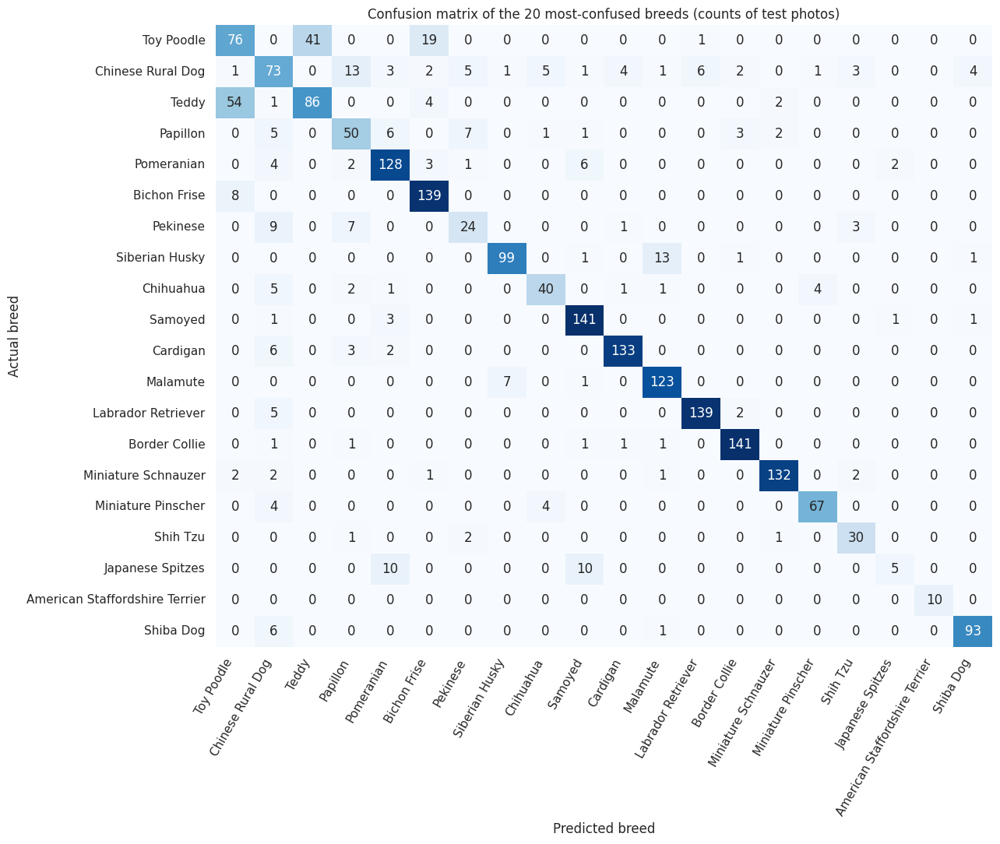

                                precision    recall  f1-score   support

                 Affenpinscher      1.000     1.000     1.000        20
                  Afghan Hound      0.964     1.000     0.982        27
           African Hunting Dog      1.000     1.000     1.000        26
                      Airedale      0.808     1.000     0.894        21
              American Bulldog      0.750     0.750     0.750        20
     American Pit Bull Terrier      0.474     0.450     0.462        20
American Staffordshire Terrier      0.476     0.455     0.465        22
                   Appenzeller      0.778     0.875     0.824        24
           Australian Shepherd      0.909     0.833     0.870        24
            Australian Terrier      0.762     0.762     0.762        21
                       Basenji      0.962     0.893     0.926        28
                        Basset      0.936     0.957     0.946        46
                        Beagle      0.865     0.900     0.882  

In [21]:
from sklearn.metrics import confusion_matrix, classification_report

cmx = confusion_matrix(y_true, pred, labels=list(range(NC)))
cmn = cmx / np.clip(cmx.sum(1, keepdims=True), 1, None)

fig, ax = plt.subplots(figsize=(17, 15))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(NC)); ax.set_yticks(range(NC))
ax.set_xticklabels(class_names, rotation=90, fontsize=4.5); ax.set_yticklabels(class_names, fontsize=4.5)
ax.set_xlabel('Predicted breed'); ax.set_ylabel('Actual breed'); ax.set_title(f'Confusion matrix, all {NC} breeds (each row sums to 1: share of that breed\'s test photos)')
plt.colorbar(im, fraction=0.025); plt.tight_layout(); savefig(fig, 'confusion_matrix.png', dpi=200); plt.show()

off = cmx.copy(); np.fill_diagonal(off, 0)
err = off.sum(0) + off.sum(1)
top = np.argsort(-err)[:20]
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cmx[np.ix_(top, top)], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=[class_names[i] for i in top], yticklabels=[class_names[i] for i in top])
ax.set_xlabel('Predicted breed'); ax.set_ylabel('Actual breed'); ax.set_title('Confusion matrix of the 20 most-confused breeds (counts of test photos)')
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); savefig(fig, 'confusion_matrix_most_confused.png'); plt.show()

rep_txt = classification_report(y_true, pred, labels=list(range(NC)), target_names=class_names, zero_division=0, digits=3)
rep = pd.DataFrame(classification_report(y_true, pred, labels=list(range(NC)), target_names=class_names, zero_division=0, output_dict=True)).T
rep.to_csv(RES / 'classification_report.csv')
(RES / 'classification_report.txt').write_text(rep_txt)
print(rep_txt)

per = rep.iloc[:NC].copy()
per['support'] = per.support.astype(int)
solid = per[per.support >= 5]
best_cls = solid.sort_values(['f1-score', 'support'], ascending=False).head(5)
worst_cls = solid.sort_values('f1-score').head(5)
FAMILIES = ['terrier', 'spaniel', 'retriever', 'poodle', 'setter', 'pointer', 'hound', 'collie', 'shepherd', 'mastiff', 'bulldog', 'corgi', 'schnauzer', 'spitz', 'husky',
            'sheepdog', 'pinscher', 'greyhound', 'whippet', 'beagle', 'bernard', 'wolfhound', 'cattle', 'sled']
pairs = []
for i, j in zip(*np.nonzero(off)):
    pairs.append((int(off[i, j]), class_names[i], class_names[j]))
pairs.sort(reverse=True)
conf_rows = []
for n, a, b in pairs[:10]:
    fam = [f for f in FAMILIES if f in a.lower() and f in b.lower()]
    conf_rows.append(dict(actual=a, predicted=b, count=n, shared_word=fam[0] if fam else ''))
print('\nBEST-PERFORMING BREEDS (>= 5 test photos, by F1):'); print(best_cls[['precision', 'recall', 'f1-score', 'support']].round(3).to_string())
print('\nWEAKEST BREEDS:'); print(worst_cls[['precision', 'recall', 'f1-score', 'support']].round(3).to_string())
print('\nMOST COMMON CONFUSIONS (actual -> predicted):')
for c in conf_rows:
    print(f'   {c["actual"]} -> {c["predicted"]}: {c["count"]} photos' + (f'  (both are "{c["shared_word"]}" breeds)' if c['shared_word'] else ''))
print('\nWhy these errors happen: (1) breeds in the same family share body shape, coat and colour, so even people confuse them; (2) some breeds have few training photos, '
      'so the model has seen fewer variations; (3) photos with several dogs, people or unusual poses add noise; (4) labels from different datasets are not perfect (the same breed '
      'can be named differently or mislabelled); (5) breeds with few test photos give noisy scores.')

tm = metrics_from_probs(y_true, probs)
tuned = dict(tm, arch=best_hp['arch'], hp=best_hp)
if FINAL_INFO:
    tuned.update(params=FINAL_INFO['params'], minutes=FINAL_INFO['minutes'], epochs_run=len(FINAL_INFO['history']['loss']))
else:
    tuned.update(params=int(model.count_params()), minutes=None, epochs_run=None)
try:
    tuned.update({k: TUNED_TRAIN[k] for k in ('diagnosis', 'train_acc', 'val_acc', 'train_loss', 'val_loss', 'best_epoch', 'head_epochs', 'history')})
except NameError:
    pass
tuned.update(best=best_cls[['precision', 'recall', 'f1-score', 'support']].round(3).reset_index().rename(columns={'index': 'breed'}).to_dict('records'),
             worst=worst_cls[['precision', 'recall', 'f1-score', 'support']].round(3).reset_index().rename(columns={'index': 'breed'}).to_dict('records'),
             confusions=conf_rows, per_source=res.groupby('source').correct.mean().round(4).to_dict(),
             n_test=int(len(y_true)), n_breeds_with_5=int(len(solid)))
RESULTS['transfer_tuned'] = tuned
if TUNE_SUMMARY_PATH.exists():
    RESULTS['tuning'] = json.loads(TUNE_SUMMARY_PATH.read_text())
if (ROOT / 'arch_leaderboard.csv').exists():
    lb = pd.read_csv(ROOT / 'arch_leaderboard.csv')
    RESULTS['leaderboard'] = lb[lb.n_classes == NC].sort_values('score', ascending=False).to_dict('records')
save_results()
print(f'\nFinal model on the test set: accuracy {tm["accuracy"]:.4f}, macro precision {tm["precision_macro"]:.4f}, macro recall {tm["recall_macro"]:.4f}, macro F1 {tm["f1_macro"]:.4f}')

## 7. Model comparison

Custom CNN, transfer learning with default settings, and transfer learning after tuning.

Model                  Custom CNN (from scratch)  Transfer learning, default settings  Transfer learning, tuned + early stopping
Accuracy                                  52.6 %                               83.9 %                                     84.2 %
Precision (macro)                         48.2 %                               84.9 %                                     85.0 %
Recall (macro)                            43.6 %                               83.7 %                                     83.7 %
F1-score (macro)                          43.5 %                               83.7 %                                     83.8 %
Top-5 accuracy                            83.4 %                               98.0 %                                     98.0 %
Training time (min)                         54.7                                 15.8                                       55.9
Parameters (millions)                       1.38                                  6.1            

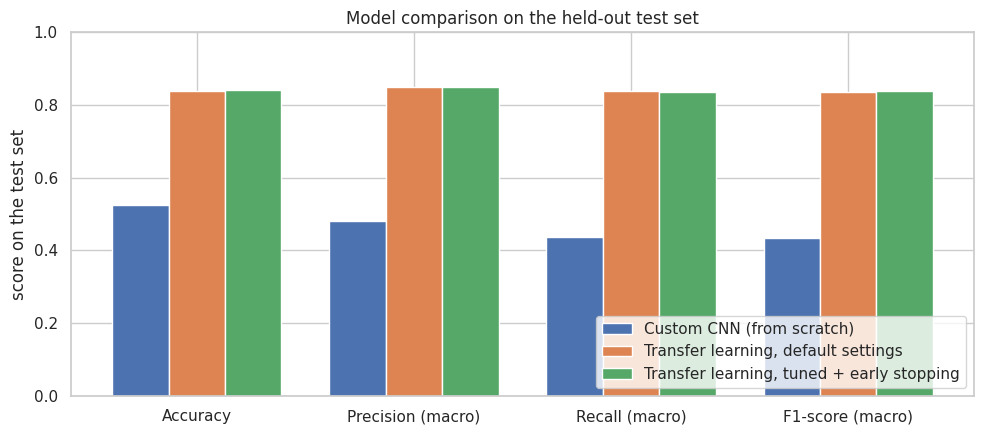


BEFORE vs AFTER OPTIMISATION: untuned transfer learning 83.9% -> tuned 84.2% (+0.2 points). Custom CNN from scratch: 52.6%; transfer learning is +31.6 points better.

Why transfer learning wins: the pretrained network already knows edges, textures, fur and body parts from over a million ImageNet photos (many of them dogs), so only a small head has to be learned from our data. The from-scratch CNN has to learn everything from about the same number of photos, spread over many breeds, which is slow and prone to confusing similar breeds. The price: the pretrained model is larger and slower to run, and Stanford Dogs photos come from ImageNet, so scores on those photos are optimistic.


In [22]:
rows = [('Custom CNN (from scratch)', RESULTS['cnn']), ('Transfer learning, default settings', RESULTS['transfer_default']), ('Transfer learning, tuned + early stopping', RESULTS['transfer_tuned'])]
tab = pd.DataFrame({
    'Model': [n for n, _ in rows],
    'Accuracy': [r['accuracy'] for _, r in rows],
    'Precision (macro)': [r['precision_macro'] for _, r in rows],
    'Recall (macro)': [r['recall_macro'] for _, r in rows],
    'F1-score (macro)': [r['f1_macro'] for _, r in rows],
    'Top-5 accuracy': [r['top5'] for _, r in rows],
    'Training time (min)': [None if r.get('minutes') is None else round(r['minutes'], 1) for _, r in rows],
    'Parameters (millions)': [round(r['params'] / 1e6, 2) for _, r in rows],
    'Epochs run': [r.get('epochs_run') for _, r in rows],
})
tab.to_csv(RES / 'model_comparison.csv', index=False)
shown = tab.copy()
for c in ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1-score (macro)', 'Top-5 accuracy']:
    shown[c] = (shown[c] * 100).round(1).astype(str) + ' %'
print(shown.T.to_string(header=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
metrics = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1-score (macro)']
w = 0.26
for k, (name, _) in enumerate(rows):
    ax.bar(np.arange(len(metrics)) + (k - 1) * w, [tab.loc[k, m] for m in metrics], w, label=name)
ax.set_xticks(range(len(metrics))); ax.set_xticklabels(metrics); ax.set_ylim(0, 1); ax.set_ylabel('score on the test set'); ax.legend(loc='lower right'); ax.set_title('Model comparison on the held-out test set')
plt.tight_layout(); savefig(fig, 'model_comparison.png'); plt.show()

a0, a1, a2 = (r['accuracy'] for _, r in rows)
print(f'\nBEFORE vs AFTER OPTIMISATION: untuned transfer learning {a1:.1%} -> tuned {a2:.1%} ({(a2 - a1) * 100:+.1f} points). '
      f'Custom CNN from scratch: {a0:.1%}; transfer learning is {(a2 - a0) * 100:+.1f} points better.')
print('\nWhy transfer learning wins: the pretrained network already knows edges, textures, fur and body parts from over a million ImageNet photos (many of them dogs), so only a small head has to be learned from '
      'our data. The from-scratch CNN has to learn everything from about the same number of photos, spread over many breeds, which is slow and prone to confusing similar breeds. '
      'The price: the pretrained model is larger and slower to run, and Stanford Dogs photos come from ImageNet, so scores on those photos are optimistic.')
RESULTS['comparison'] = tab.to_dict('records')
save_results()

## 8. Predictions on new images

Test-set photos, which the model never saw in training, validation or tuning. Each is loaded, resized and preprocessed like the training data, and the model returns the breed with its confidence.

Image: test_01_Airedale.jpg
   Actual breed:    Airedale
   Predicted Breed: Airedale
   Confidence: 93.91%   OK

Image: test_02_Shiba_Inu.jpg
   Actual breed:    Shiba Inu
   Predicted Breed: Shiba Dog
   Confidence: 59.08%   WRONG

Image: test_03_Chinese_Crested_Dog.jpg
   Actual breed:    Chinese Crested Dog
   Predicted Breed: Pomeranian
   Confidence: 24.78%   WRONG

Image: test_04_Curly_Coated_Retriever.jpg
   Actual breed:    Curly Coated Retriever
   Predicted Breed: Curly Coated Retriever
   Confidence: 82.73%   OK

Image: test_05_Lakeland_Terrier.jpg
   Actual breed:    Lakeland Terrier
   Predicted Breed: Lakeland Terrier
   Confidence: 86.44%   OK

Image: test_06_Rhodesian_Ridgeback.jpg
   Actual breed:    Rhodesian Ridgeback
   Predicted Breed: Rhodesian Ridgeback
   Confidence: 78.22%   OK

Image: test_07_Komondor.jpg
   Actual breed:    Komondor
   Predicted Breed: Komondor
   Confidence: 90.02%   OK

Image: test_08_Cocker_Spaniel.jpg
   Actual breed:    Cocker Spaniel
 

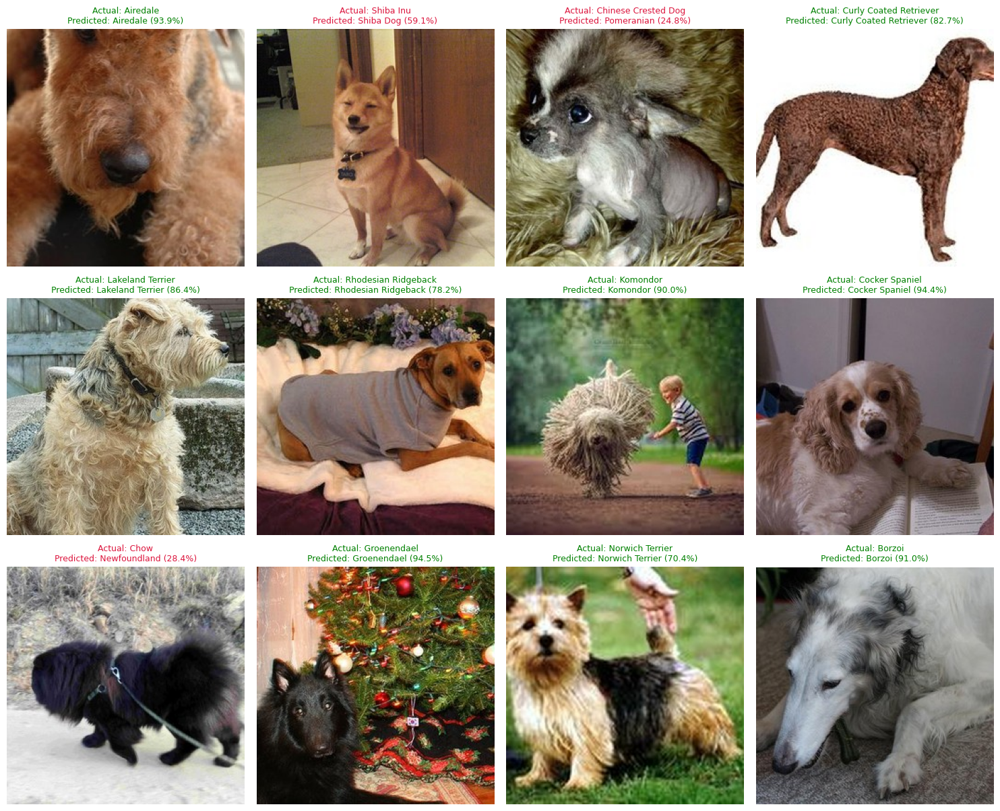

9 of 12 unseen photos were predicted correctly.


In [23]:
n_new = CFG['n_new_images']
per_breed_one = test_df.groupby('breed', group_keys=False).sample(1, random_state=SEED + 1)
chosen = per_breed_one.sample(n=min(n_new, len(per_breed_one)), random_state=SEED + 2).reset_index(drop=True)
for old_f in (PROJ / 'test_images').glob('test_*.jpg'):
    old_f.unlink()
records = []
ncols = 4
fig, axes = plt.subplots(math.ceil(len(chosen) / ncols), ncols, figsize=(15, 4.1 * math.ceil(len(chosen) / ncols)))
for a in np.ravel(axes):
    a.axis('off')
for k, (a, r) in enumerate(zip(np.ravel(axes), chosen.itertuples())):
    fname = f'test_{k + 1:02d}_{re.sub(r"[^A-Za-z0-9]+", "_", r.breed)}.jpg'
    shutil.copy(r.path, PROJ / 'test_images' / fname)
    sq, x = load_for_inference(PROJ / 'test_images' / fname)
    p = model.predict(x[None], verbose=0)[0]
    top = np.argsort(-p)[:3]
    ok = class_names[top[0]] == r.breed
    records.append(dict(file=fname, actual=r.breed, predicted=class_names[top[0]], confidence=float(p[top[0]]), correct=bool(ok),
                        top3=[(class_names[i], float(p[i])) for i in top]))
    print(f'Image: {fname}\n   Actual breed:    {r.breed}\n   Predicted Breed: {class_names[top[0]]}\n   Confidence: {p[top[0]]:.2%}   {"OK" if ok else "WRONG"}\n')
    a.imshow(sq); a.axis('off')
    a.set_title(f'Actual: {r.breed}\nPredicted: {class_names[top[0]]} ({p[top[0]]:.1%})', fontsize=9, color='green' if ok else 'crimson')
plt.tight_layout(); savefig(fig, 'predictions.png'); plt.show()
n_ok = sum(r['correct'] for r in records)
print(f'{n_ok} of {len(records)} unseen photos were predicted correctly.')
RESULTS['new_images'] = records
save_results()

## 9. Saving and deployment

The model is saved in Keras format, converted to TensorFlow Lite and served with FastAPI. The cell starts the service, sends it photos and prints the replies.

In [24]:
if HAVE_SAVED_MODEL:
    print('The model is already saved on Drive.')
else:
    model_path = ROOT / 'dog_breed_model.keras'
    model.save(model_path)
    (ROOT / 'class_names.json').write_text(json.dumps(class_names))
    (ROOT / 'best_hp.json').write_text(json.dumps(best_hp, indent=2))
    if PERSIST:
        shutil.copy(ROOT / 'best_hp.json', PERSIST / 'best_hp.json')
        shutil.copy(model_path, PERSIST / 'dog_breed_model.keras')
        shutil.copy(ROOT / 'class_names.json', PERSIST / 'class_names.json')
        print('Model + class names saved to Drive:', PERSIST)
    try:
        from google.colab import files
        files.download(str(model_path))
        files.download(str(ROOT / 'class_names.json'))
    except Exception:
        pass

The model is already saved on Drive.


In [25]:
import tensorflow as tf

TFLITE_FILE = ROOT / 'transfer_learning_model.tflite'
if PERSIST and (PERSIST / 'transfer_learning_model.tflite').exists() and not TFLITE_FILE.exists():
    shutil.copy(PERSIST / 'transfer_learning_model.tflite', TFLITE_FILE)


def convert_to_tflite(model):
    prev_policy = keras.mixed_precision.global_policy().name
    prev_pre = CFG['pretrained']
    keras.mixed_precision.set_global_policy('float32')
    CFG['pretrained'] = None
    try:
        clone, _ = build_model(dict(best_hp, no_augment=True))
    finally:
        CFG['pretrained'] = prev_pre
        keras.mixed_precision.set_global_policy(prev_policy)
    src_layers = [l for l in model.layers if not l.name.startswith('augment')]
    dst_layers = [l for l in clone.layers if not l.name.startswith('augment')]
    assert len(src_layers) == len(dst_layers), f'layer lists differ ({len(src_layers)} vs {len(dst_layers)})'
    for a_, b_ in zip(src_layers, dst_layers):
        w_ = a_.get_weights()
        if w_:
            b_.set_weights(w_)
    exp_dir = ROOT / 'saved_model_export'
    shutil.rmtree(exp_dir, ignore_errors=True)
    try:
        clone.export(str(exp_dir))
    except Exception as e:
        print('  (SavedModel export failed, that route is skipped:', str(e)[:120], ')')

    @tf.function(input_signature=[tf.TensorSpec([1, IMG, IMG, 3], tf.float32)])
    def serve(x):
        return clone(x, training=False)

    routes = [('SavedModel', lambda: tf.lite.TFLiteConverter.from_saved_model(str(exp_dir))),
              ('fixed batch size 1', lambda: tf.lite.TFLiteConverter.from_concrete_functions([serve.get_concrete_function()], clone)),
              ('Keras model', lambda: tf.lite.TFLiteConverter.from_keras_model(clone))]
    for rname, make in routes:
        for f16 in (True, False):
            label = f'{rname}, {"float16" if f16 else "float32"} weights'
            try:
                conv = make()
                if f16:
                    conv.optimizations = [tf.lite.Optimize.DEFAULT]
                    conv.target_spec.supported_types = [tf.float16]
                data = conv.convert()
                print('  TensorFlow Lite conversion worked:', label)
                return data, label
            except Exception as e:
                msg = str(e)
                short = [l.strip()[:220] for l in msg.split('\n') if 'error' in l.lower()][:2] or [msg.strip()[:220]]
                print(f'  attempt failed ({label}):', ' | '.join(short))
    return None, None


TFLITE_OK = False
if RESULTS.get('deploy', {}).get('tflite_ok') and TFLITE_FILE.exists() and not CFG['retrain']:
    TFLITE_OK = True
    print('TensorFlow Lite model already converted (restored from Drive).')
else:
    tfl_bytes, tfl_how = convert_to_tflite(model)
    if tfl_bytes is not None:
        TFLITE_FILE.write_bytes(tfl_bytes)
        TFLITE_OK = True
        if PERSIST:
            shutil.copy(TFLITE_FILE, PERSIST / 'transfer_learning_model.tflite')
    else:
        print('\nTensorFlow Lite conversion did not work on this setup. The service in the next cell will serve the Keras model instead '
              '(FastAPI with the Keras model is an accepted deployment). Send the first lines of the error above if you want the TFLite version fixed.')

kp = ROOT / 'dog_breed_model.keras'
if not kp.exists() and PERSIST:
    kp = PERSIST / 'dog_breed_model.keras'
keras_mb = kp.stat().st_size / 1e6 if kp.exists() else 0.0

if TFLITE_OK:
    interp = tf.lite.Interpreter(model_path=str(TFLITE_FILE))
    interp.allocate_tensors()
    i_det, o_det = interp.get_input_details()[0], interp.get_output_details()[0]
    check_df = test_df.sample(n=min(60, len(test_df)), random_state=SEED)
    agree, diffs, times = 0, [], []
    for r in check_df.itertuples():
        _, x = load_for_inference(r.path)
        pk = model.predict(x[None], verbose=0)[0]
        t0 = time.time()
        interp.set_tensor(i_det['index'], x[None].astype(i_det['dtype']))
        interp.invoke()
        pt = interp.get_tensor(o_det['index'])[0]
        times.append((time.time() - t0) * 1000)
        agree += int(pk.argmax() == pt.argmax())
        diffs.append(float(np.abs(pk - pt).max()))
    RESULTS['deploy'] = dict(tflite_ok=True, tflite_mb=TFLITE_FILE.stat().st_size / 1e6, keras_mb=keras_mb, agreement=agree / len(check_df),
                             max_prob_diff=float(max(diffs)), latency_ms=float(np.mean(times)), n_checked=int(len(check_df)))
    d = RESULTS['deploy']
    print(f'TensorFlow Lite model: {d["tflite_mb"]:.1f} MB (Keras model: {d["keras_mb"]:.1f} MB). Same predicted breed as the Keras model on {d["agreement"]:.1%} of {d["n_checked"]} test photos; '
          f'largest probability difference {d["max_prob_diff"]:.4f}; about {d["latency_ms"]:.0f} ms per photo on this machine.')
else:
    RESULTS['deploy'] = dict(tflite_ok=False, keras_mb=keras_mb)
save_results()

TensorFlow Lite model already converted (restored from Drive).


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TensorFlow Lite model: 12.2 MB (Keras model: 82.8 MB). Same predicted breed as the Keras model on 100.0% of 60 test photos; largest probability difference 0.0027; about 45 ms per photo on this machine.


In [26]:
APP_PY = r'''# FastAPI service for the dog breed classifier (TensorFlow Lite model, or the Keras model when no .tflite file is present).
#
# Start:  uvicorn app:app --host 0.0.0.0 --port 8000
# Docs:   http://localhost:8000/docs
# Test:   curl -F "file=@dog.jpg" http://localhost:8000/predict
import io
import json
import threading
from pathlib import Path

import numpy as np
import tensorflow as tf
from fastapi import FastAPI, File, HTTPException, UploadFile
from PIL import Image, ImageOps

HERE = Path(__file__).parent
CLASS_NAMES = json.loads((HERE / 'class_names.json').read_text())
STORE = 256            # images were stored at 256x256 for training
UNSURE_BELOW = 0.35    # below this confidence the answer is flagged as unsure

if (HERE / 'model.tflite').exists():
    interpreter = tf.lite.Interpreter(model_path=str(HERE / 'model.tflite'))
    interpreter.allocate_tensors()
    IN = interpreter.get_input_details()[0]
    OUT = interpreter.get_output_details()[0]
    IMG = int(IN['shape'][1])

    def run_model(x):
        interpreter.set_tensor(IN['index'], x.astype(IN['dtype']))
        interpreter.invoke()
        return interpreter.get_tensor(OUT['index'])[0].astype(float)
else:
    import keras
    KERAS_MODEL = keras.models.load_model(HERE / 'model.keras')
    IMG = int(KERAS_MODEL.input_shape[1])

    def run_model(x):
        return KERAS_MODEL.predict(x, verbose=0)[0].astype(float)

lock = threading.Lock()        # one request at a time

app = FastAPI(title='Dog Breed Classifier', version='1.0')


def preprocess(im):
    # same steps as in training: fix rotation, RGB, short side -> 256, centre crop 256, centre crop 224
    im = ImageOps.exif_transpose(im).convert('RGB')
    w, h = im.size
    s = STORE / min(w, h)
    im = im.resize((max(STORE, round(w * s)), max(STORE, round(h * s))), Image.LANCZOS)
    w, h = im.size
    l, t = (w - STORE) // 2, (h - STORE) // 2
    im = im.crop((l, t, l + STORE, t + STORE))
    off = (STORE - IMG) // 2
    im = im.crop((off, off, off + IMG, off + IMG))
    return np.asarray(im, dtype=np.float32)[None]


@app.get('/health')
def health():
    return {'status': 'ok', 'classes': len(CLASS_NAMES), 'input_size': IMG}


@app.post('/predict')
async def predict(file: UploadFile = File(...), top_k: int = 5):
    data = await file.read()
    try:
        im = Image.open(io.BytesIO(data))
        im.load()
    except Exception:
        raise HTTPException(status_code=400, detail='The upload is not a readable image.')
    x = preprocess(im)
    with lock:
        p = run_model(x)
    top = np.argsort(-p)[:max(1, min(top_k, len(CLASS_NAMES)))]
    best = int(top[0])
    return {
        'filename': file.filename,
        'predicted_breed': CLASS_NAMES[best] if p[best] >= UNSURE_BELOW else 'unsure',
        'best_guess': CLASS_NAMES[best],
        'confidence': round(float(p[best]), 4),
        'top_k': [{'breed': CLASS_NAMES[int(i)], 'probability': round(float(p[int(i)]), 4)} for i in top],
    }
'''

PREDICT_PY = r'''# Predict the breed of one or more dog photos with the saved Keras model.
#
# Usage:  python prediction.py dog1.jpg dog2.jpg
#         python prediction.py dog.jpg --model ../models/transfer_learning_model.keras --classes ../models/class_names.json --top 5
import argparse
import json
from pathlib import Path

import keras
import numpy as np
from PIL import Image, ImageOps

STORE = 256            # images were stored at 256x256 for training
UNSURE_BELOW = 0.35    # below this confidence the answer is flagged as unsure


def load_image(path, img):
    # load -> fix rotation -> RGB -> short side 256 -> centre crop 256 -> centre crop to the network size
    im = ImageOps.exif_transpose(Image.open(path)).convert('RGB')
    w, h = im.size
    s = STORE / min(w, h)
    im = im.resize((max(STORE, round(w * s)), max(STORE, round(h * s))), Image.LANCZOS)
    w, h = im.size
    l, t = (w - STORE) // 2, (h - STORE) // 2
    im = im.crop((l, t, l + STORE, t + STORE))
    off = (STORE - img) // 2
    return np.asarray(im.crop((off, off, off + img, off + img)), dtype=np.float32)


def main():
    here = Path(__file__).resolve().parent
    ap = argparse.ArgumentParser()
    ap.add_argument('images', nargs='+')
    ap.add_argument('--model', default=str(here.parent / 'models' / 'transfer_learning_model.keras'))
    ap.add_argument('--classes', default=str(here.parent / 'models' / 'class_names.json'))
    ap.add_argument('--top', type=int, default=5)
    a = ap.parse_args()
    model = keras.models.load_model(a.model)
    names = json.loads(Path(a.classes).read_text())
    img = model.input_shape[1]
    for path in a.images:
        p = model.predict(load_image(path, img)[None], verbose=0)[0]
        top = np.argsort(-p)[:a.top]
        print(f'Image: {Path(path).name}')
        print(f'Predicted Breed: {names[top[0]] if p[top[0]] >= UNSURE_BELOW else "unsure (mixed breed or not a dog?)"}')
        print(f'Confidence: {p[top[0]]:.2%}')
        print('Top guesses: ' + ', '.join(f'{names[i]} {p[i]:.1%}' for i in top))
        print()


if __name__ == '__main__':
    main()
'''

DEP = PROJ / 'deployment'
(DEP / 'app.py').write_text(APP_PY)
for old_m in ('model.tflite', 'model.keras'):
    (DEP / old_m).unlink(missing_ok=True)
if TFLITE_OK:
    shutil.copy(TFLITE_FILE, DEP / 'model.tflite')
else:
    kp_ = ROOT / 'dog_breed_model.keras'
    shutil.copy(kp_ if kp_.exists() else PERSIST / 'dog_breed_model.keras', DEP / 'model.keras')
(DEP / 'class_names.json').write_text(json.dumps(class_names))
(PROJ / 'src' / 'prediction.py').write_text(PREDICT_PY)
(DEP / 'requirements.txt').write_text('tensorflow\nfastapi\nuvicorn\npython-multipart\npillow\nnumpy\n')
(DEP / 'README.md').write_text('# Dog breed API\n\n```\npip install -r requirements.txt\nuvicorn app:app --host 0.0.0.0 --port 8000\n```\n\nOpen http://localhost:8000/docs to try it in the browser, or:\n\n'
                               '```\ncurl -F "file=@dog.jpg" http://localhost:8000/predict\n```\n')
print('Wrote', DEP / 'app.py', 'and', PROJ / 'src' / 'prediction.py')

import sys, requests
PORT = 8765
logf = open(ROOT / 'uvicorn.log', 'w')
srv = subprocess.Popen([sys.executable, '-m', 'uvicorn', 'app:app', '--port', str(PORT)], cwd=DEP, stdout=logf, stderr=subprocess.STDOUT)
api_results = []
try:
    up = False
    for _ in range(90):
        try:
            if requests.get(f'http://127.0.0.1:{PORT}/health', timeout=2).ok:
                up = True
                break
        except Exception:
            pass
        time.sleep(2)
    assert up, 'the API did not start; see ' + str(ROOT / 'uvicorn.log')
    print('GET /health ->', requests.get(f'http://127.0.0.1:{PORT}/health').json())
    for r in chosen.head(4).itertuples():
        with open(r.path, 'rb') as fh:
            reply = requests.post(f'http://127.0.0.1:{PORT}/predict', files={'file': (Path(r.path).name, fh, 'image/jpeg')}).json()
        api_results.append(dict(actual=r.breed, reply=reply))
        print(f'\nPOST /predict  (photo of a {r.breed})\n', json.dumps(reply, indent=2))
    bad = requests.post(f'http://127.0.0.1:{PORT}/predict', files={'file': ('notes.txt', b'not an image', 'text/plain')})
    print(f'\nPOST /predict with a text file -> HTTP {bad.status_code}: {bad.json()}')
    RESULTS['api_test'] = dict(ok=True, replies=api_results, bad_upload_status=bad.status_code)
except Exception as e:
    print('API test failed:', e)
    print(open(ROOT / 'uvicorn.log').read()[-1500:])
    RESULTS['api_test'] = dict(ok=False, error=str(e)[:300])
finally:
    srv.terminate()
    logf.close()
save_results()

Wrote /content/dogs/Dog_Image_Classification/deployment/app.py and /content/dogs/Dog_Image_Classification/src/prediction.py
GET /health -> {'status': 'ok', 'classes': 138, 'input_size': 224}

POST /predict  (photo of a Airedale)
 {
  "filename": "0005226.jpg",
  "predicted_breed": "Airedale",
  "best_guess": "Airedale",
  "confidence": 0.9389,
  "top_k": [
    {
      "breed": "Airedale",
      "probability": 0.9389
    },
    {
      "breed": "Lakeland Terrier",
      "probability": 0.0067
    },
    {
      "breed": "Irish Terrier",
      "probability": 0.0047
    },
    {
      "breed": "Wire Haired Fox Terrier",
      "probability": 0.0043
    },
    {
      "breed": "Standard Poodle",
      "probability": 0.0018
    }
  ]
}

POST /predict  (photo of a Shiba Inu)
 {
  "filename": "0021058.jpg",
  "predicted_breed": "Shiba Dog",
  "best_guess": "Shiba Dog",
  "confidence": 0.5909,
  "top_k": [
    {
      "breed": "Shiba Dog",
      "probability": 0.5909
    },
    {
      "breed": 

## 10. Try your own photos

Choose one or more dog photos; the five most likely breeds are shown. Low-confidence answers are marked as unsure.

Saving 360_F_369157684_flMLtkW3RES1kqdw3F0vV68T1aIuKdOq.jpg to 360_F_369157684_flMLtkW3RES1kqdw3F0vV68T1aIuKdOq.jpg
Image: 360_F_369157684_flMLtkW3RES1kqdw3F0vV68T1aIuKdOq.jpg
Predicted Breed: English Foxhound
Confidence: 71.14%


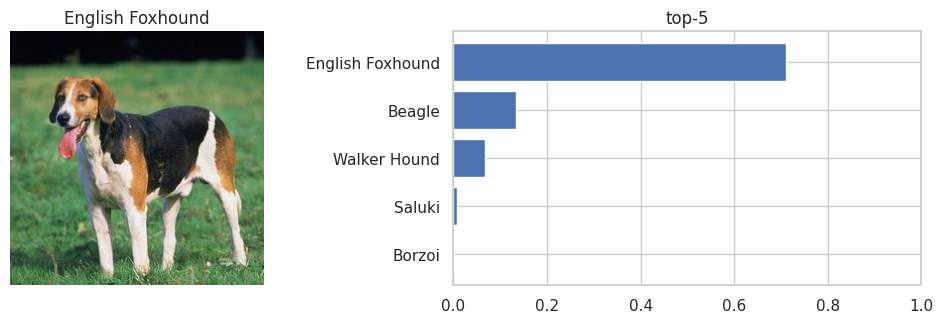

In [27]:
UNSURE_BELOW = 0.35


def load_for_inference(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
    sq = to_square(im, S)
    off = (S - IMG) // 2
    crop = sq.crop((off, off, off + IMG, off + IMG))
    return sq, np.asarray(crop, dtype=np.float32)


from google.colab import files
uploaded = files.upload()
(PROJ / 'test_images' / 'uploads').mkdir(exist_ok=True)
RESULTS['uploaded'] = []
for name in uploaded:
    shutil.copy(name, PROJ / 'test_images' / 'uploads' / Path(name).name)
    sq, x = load_for_inference(name)
    p = model.predict(x[None], verbose=0)[0]
    top = np.argsort(-p)[:5]
    verdict = class_names[top[0]] if p[top[0]] >= UNSURE_BELOW else 'unsure (mixed breed or not a dog?)'
    print(f'Image: {name}\nPredicted Breed: {verdict}\nConfidence: {p[top[0]]:.2%}')
    RESULTS['uploaded'].append(dict(file=name, predicted=class_names[top[0]], confidence=float(p[top[0]])))
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={'width_ratios': [1, 1.4]})
    ax[0].imshow(sq); ax[0].axis('off'); ax[0].set_title(verdict)
    ax[1].barh([class_names[i] for i in top][::-1], p[top][::-1]); ax[1].set_xlim(0, 1); ax[1].set_title('top-5')
    plt.tight_layout(); plt.show()
save_results()